# Diabetes Hospital Analytics: Length-of-Stay & Medication Prediction

End-to-end machine learning on **101,766 hospital encounters of diabetic patients** (UCI *Diabetes 130-US Hospitals* dataset):

1. **EDA** with SQL and Python
2. **Data cleaning & preprocessing** (missing values, diagnosis-code mapping, encoding)
3. **Regression**: predict `time_in_hospital` (Linear, Ridge, Lasso, Decision Tree, Gradient Boosting, XGBoost)
4. **Classification**: predict `diabetesMed` (Logistic Regression, Random Forest, KNN)
5. **Clustering**: K-Means, Agglomerative, DBSCAN with PCA visualisation
6. **Feature engineering, feature selection & hyperparameter tuning** (GridSearchCV, nested CV)

See the [README](README.md) for a summary of results.

## Project Overview
This project focuses on the analysis of diabetes patient data in order to apply in machine learning algorithms. <br>
It will involve the students working on a wide variety of machine learning techniques, ranging from basic data analysis to the optimisation of advanced models. 


## Required Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



## *Task 1: Exploratory Data Analysis (EDA) with Python and SQL
_________


### **Task 1A: Exploratory Data Analysis with SQL**

### Task Description
Etablish a connection between Python and a database with performing basic operations using SQL and perform exploratory data analysis with sql to understand the dataset's characteristics, patterns.

### Task 1A.1: General Overview of the Data

In [2]:

# # #  Count the total number of records in the encounter table .
'''
SELECT COUNT(*) as total_records 
FROM encounter;
'''

'\nSELECT COUNT(*) as total_records \nFROM encounter;\n'

In [3]:
# # # # Check the distribution of different admission types 
'''
SELECT admission_type_id, COUNT(*) as different_admission_types
FROM encounter
GROUP BY admission_type_id
ORDER BY different_admission_types DESC;
'''

'\nSELECT admission_type_id, COUNT(*) as different_admission_types\nFROM encounter\nGROUP BY admission_type_id\nORDER BY different_admission_types DESC;\n'

In [4]:
# # # # Explore the top discharge dispositions 
'''
SELECT 
    discharge_disposition_id, 
    COUNT(*) AS total_count
FROM 
    encounter
GROUP BY 
    discharge_disposition_id
ORDER BY 
    total_count DESC;
    '''

'\nSELECT \n    discharge_disposition_id, \n    COUNT(*) AS total_count\nFROM \n    encounter\nGROUP BY \n    discharge_disposition_id\nORDER BY \n    total_count DESC;\n    '

### Task 1A.2: Identifying Missing or Anomalous Data

In [5]:
# # # Check for missing values in the race column (Hint: Count the occurance of each unique value in this column)
'''
SELECT 
    race , 
    COUNT(*) AS total_count
FROM 
    patient 
GROUP BY 
    race;


# # # Check for missing or unusual values in the weight column
SELECT 
    weight, 
    COUNT(*) AS total_count
FROM 
    patient 
GROUP BY 
    weight
ORDER BY 
    weight;
    '''

'\nSELECT \n    race , \n    COUNT(*) AS total_count\nFROM \n    patient \nGROUP BY \n    race;\n\n\n# # # Check for missing or unusual values in the weight column\nSELECT \n    weight, \n    COUNT(*) AS total_count\nFROM \n    patient \nGROUP BY \n    weight\nORDER BY \n    weight;\n    '

### Task 1A.3: Understanding Age Distribution

In [6]:
# # # Explore the age distribution of the patients
'''
SELECT 
    age, 
    COUNT(*) AS total_count
FROM 
    patient
GROUP BY 
    age
ORDER BY 
    age
    '''

'\nSELECT \n    age, \n    COUNT(*) AS total_count\nFROM \n    patient\nGROUP BY \n    age\nORDER BY \n    age\n    '

### Task 1A.4: Admission Trends by Source and Type

In [7]:
# # # Analyze how different admission sources contribute to hospital admissions 
# # # (Hint: Calculate the number of admissions per source)
'''
SELECT admission_source_id , COUNT(*) AS num_admissions
FROM encounter
GROUP BY admission_source_id 
ORDER BY num_admissions DESC;


#Investigate which admission types correspond to specific admission sources
# # # (Hint: add admission type to your previous query)
SELECT admission_source_id , admission_type_id , COUNT(*) AS num_admissions
FROM encounter
GROUP BY admission_source_id , admission_type_id 
ORDER BY admission_source_id , admission_type_id ;
'''

'\nSELECT admission_source_id , COUNT(*) AS num_admissions\nFROM encounter\nGROUP BY admission_source_id \nORDER BY num_admissions DESC;\n\n\n#Investigate which admission types correspond to specific admission sources\n# # # (Hint: add admission type to your previous query)\nSELECT admission_source_id , admission_type_id , COUNT(*) AS num_admissions\nFROM encounter\nGROUP BY admission_source_id , admission_type_id \nORDER BY admission_source_id , admission_type_id ;\n'

### Task 1A.5: Hospital Stay and Readmission Patterns

In [8]:
# # #Find the average time in hospital for each admission type
'''
SELECT 
admission_type_id , 
AVG(time_in_hospital) AS average_time_in_hospital
FROM 
 encounter 
GROUP BY 
admission_type_id ;

# # # Investigate readmission rates by admission type

    #Your code here
SELECT admission_type.description AS admission_type_description,
    COUNT(CASE WHEN encounter.readmitted = '<30' THEN 1 END) AS readmissions,
    ROUND((COUNT(CASE WHEN encounter.readmitted = '<30' THEN 1 END) * 100.0) / COUNT(*), 2) AS readmission_rate_percentage
FROM encounter
JOIN admission_type ON encounter.admission_type_id = admission_type.admission_type_id
GROUP BY admission_type.description
ORDER BY readmission_rate_percentage DESC;
 '''

"\nSELECT \nadmission_type_id , \nAVG(time_in_hospital) AS average_time_in_hospital\nFROM \n encounter \nGROUP BY \nadmission_type_id ;\n\n# # # Investigate readmission rates by admission type\n\n    #Your code here\nSELECT admission_type.description AS admission_type_description,\n    COUNT(CASE WHEN encounter.readmitted = '<30' THEN 1 END) AS readmissions,\n    ROUND((COUNT(CASE WHEN encounter.readmitted = '<30' THEN 1 END) * 100.0) / COUNT(*), 2) AS readmission_rate_percentage\nFROM encounter\nJOIN admission_type ON encounter.admission_type_id = admission_type.admission_type_id\nGROUP BY admission_type.description\nORDER BY readmission_rate_percentage DESC;\n "

### Task 1A.6: Comparing Admission Types and Outcomes

In [9]:
# # # Compare discharge dispositions across different admission types
'''
SELECT 
    admission_type_id,
    discharge_disposition_id ,
    COUNT(*) AS count_dispositions
FROM 
  encounter e 
GROUP BY 
    admission_type_id , discharge_disposition_id 
ORDER BY 
  admission_type_id , count_dispositions DESC;

# # # Compare readmission rates by discharge disposition

    #Your code here
SELECT discharge_disposition.description AS discharge_disposition_description,
    ROUND((COUNT(CASE WHEN encounter.readmitted = '<30' THEN 1 END) * 100.0) / COUNT(*), 2) AS readmission_rate_percentage
FROM encounter
JOIN discharge_disposition ON encounter.discharge_disposition_id = discharge_disposition.discharge_disposition_id
GROUP BY discharge_disposition.description
ORDER BY readmission_rate_percentage DESC;
'''
  

"\nSELECT \n    admission_type_id,\n    discharge_disposition_id ,\n    COUNT(*) AS count_dispositions\nFROM \n  encounter e \nGROUP BY \n    admission_type_id , discharge_disposition_id \nORDER BY \n  admission_type_id , count_dispositions DESC;\n\n# # # Compare readmission rates by discharge disposition\n\n    #Your code here\nSELECT discharge_disposition.description AS discharge_disposition_description,\n    ROUND((COUNT(CASE WHEN encounter.readmitted = '<30' THEN 1 END) * 100.0) / COUNT(*), 2) AS readmission_rate_percentage\nFROM encounter\nJOIN discharge_disposition ON encounter.discharge_disposition_id = discharge_disposition.discharge_disposition_id\nGROUP BY discharge_disposition.description\nORDER BY readmission_rate_percentage DESC;\n"

+++++
### **Task 1B: Exploratory Data Analysis with Python**

### Task Description
Perform comprehensive exploratory data analysis to understand the dataset's characteristics, patterns, and potential challenges. <br>
It is crucial to understand the structure and quality of the dataset before diving into any analysis or modeling.

### 1B.1: Loading and analysing the dataset shape:

In [10]:
# # #  Load the dataset

import pandas as pd

df = pd.read_csv("data/diabetic_data.csv")

# # #  Display first few rows

df.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [11]:
# # # data last few rows

df.tail()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
101761,443847548,100162476,AfricanAmerican,Male,[70-80),?,1,3,7,3,...,No,Down,No,No,No,No,No,Ch,Yes,>30
101762,443847782,74694222,AfricanAmerican,Female,[80-90),?,1,4,5,5,...,No,Steady,No,No,No,No,No,No,Yes,NO
101763,443854148,41088789,Caucasian,Male,[70-80),?,1,1,7,1,...,No,Down,No,No,No,No,No,Ch,Yes,NO
101764,443857166,31693671,Caucasian,Female,[80-90),?,2,3,7,10,...,No,Up,No,No,No,No,No,Ch,Yes,NO
101765,443867222,175429310,Caucasian,Male,[70-80),?,1,1,7,6,...,No,No,No,No,No,No,No,No,No,NO


In [12]:
# #  #  inspecting the data 
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      101766 non-null  object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    101766 non-null  object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                101766 non-null  object
 11  medical_specialty         101766 non-null  object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int64 
 14  num_

In [13]:
# # # descriptive statistics summary.

df.describe()

,encounter_id,patient_nbr,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,1.017660e+05,1.017660e+05,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,1.652016e+08,5.433040e+07,2.024006,3.715642,5.754437,4.395987,43.095641,1.339730,16.021844,0.369357,0.197836,0.635566,7.422607
std,1.026403e+08,3.869636e+07,1.445403,5.280166,4.064081,2.985108,19.674362,1.705807,8.127566,1.267265,0.930472,1.262863,1.933600
min,1.252200e+04,1.350000e+02,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,8.496119e+07,2.341322e+07,1.000000,1.000000,1.000000,2.000000,31.000000,0.000000,10.000000,0.000000,0.000000,0.000000,6.000000
50%,1.523890e+08,4.550514e+07,1.000000,1.000000,7.000000,4.000000,44.000000,1.000000,15.000000,0.000000,0.000000,0.000000,8.000000
75%,2.302709e+08,8.754595e+07,3.000000,4.000000,7.000000,6.000000,57.000000,2.000000,20.000000,0.000000,0.000000,1.000000,9.000000
max,4.438672e+08,1.895026e+08,8.000000,28.000000,25.000000,14.000000,132.000000,6.000000,81.000000,42.000000,76.000000,21.000000,16.000000


In [14]:
# # #  Dataset shape 

print("Dataset shape:",df.shape)

# # # Column names

print(" Columns names:",df.columns)

Dataset shape: (101766, 50)
 Columns names: Index(['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight',
       'admission_type_id', 'discharge_disposition_id', 'admission_source_id',
       'time_in_hospital', 'payer_code', 'medical_specialty',
       'num_lab_procedures', 'num_procedures', 'num_medications',
       'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1',
       'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult',
       'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
       'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
       'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
       'tolazamide', 'examide', 'citoglipton', 'insulin',
       'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted'],
      dtype='object')


In [15]:
 # # # Identifying missing values.
print(df.isnull().sum())


encounter_id                    0
patient_nbr                     0
race                            0
gender                          0
age                             0
weight                          0
admission_type_id               0
discharge_disposition_id        0
admission_source_id             0
time_in_hospital                0
payer_code                      0
medical_specialty               0
num_lab_procedures              0
num_procedures                  0
num_medications                 0
number_outpatient               0
number_emergency                0
number_inpatient                0
diag_1                          0
diag_2                          0
diag_3                          0
number_diagnoses                0
max_glu_serum               96420
A1Cresult                   84748
metformin                       0
repaglinide                     0
nateglinide                     0
chlorpropamide                  0
glimepiride                     0
acetohexamide 

### 1B.2: Load and Explore a Dataset Using NumPy

In [16]:
# # # Load the dataset

import numpy as np

mdata = np.genfromtxt("D:\\myfile\\Block - B\\Deliverables\\diabetic_data.csv", delimiter=",", skip_header=1, dtype=None, encoding='utf-8')

# # # Checking the shape of the dataset 

print(type(mdata))  
print("Dataset shape:", mdata.shape)

# # # Preview the first few rows

print("First 5 rows of the dataset:\n" ,mdata[:5])

<class 'numpy.ndarray'>
Dataset shape: (101766,)
First 5 rows of the dataset:
 [(2278392,  8222157, 'Caucasian', 'Female', '[0-10)', '?', 6, 25, 1, 1, '?', 'Pediatrics-Endocrinology', 41, 0,  1, 0, 0, 0, '250.83', '?', '?', 1, 'None', 'None', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'NO')
 ( 149190, 55629189, 'Caucasian', 'Female', '[10-20)', '?', 1,  1, 7, 3, '?', '?', 59, 0, 18, 0, 0, 0, '276', '250.01', '255', 9, 'None', 'None', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'Up', 'No', 'No', 'No', 'No', 'No', 'Ch', 'Yes', '>30')
 (  64410, 86047875, 'AfricanAmerican', 'Female', '[20-30)', '?', 1,  1, 7, 2, '?', '?', 11, 5, 13, 2, 0, 1, '648', '250', 'V27', 6, 'None', 'None', 'No', 'No', 'No', 'No', 'No', 'No', 'Steady', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 

### 1B.3: Analysing data types:

In [17]:
# # # Data types

print("Data types:",df.dtypes)

# # # Unique values in categorical columns

print ('Unique values in:\n',df.nunique())


Data types: encounter_id                 int64
patient_nbr                  int64
race                        object
gender                      object
age                         object
weight                      object
admission_type_id            int64
discharge_disposition_id     int64
admission_source_id          int64
time_in_hospital             int64
payer_code                  object
medical_specialty           object
num_lab_procedures           int64
num_procedures               int64
num_medications              int64
number_outpatient            int64
number_emergency             int64
number_inpatient             int64
diag_1                      object
diag_2                      object
diag_3                      object
number_diagnoses             int64
max_glu_serum               object
A1Cresult                   object
metformin                   object
repaglinide                 object
nateglinide                 object
chlorpropamide              object
glimepir

### 1B.4: Exploratory Data Analysis (EDA) with Visualisations

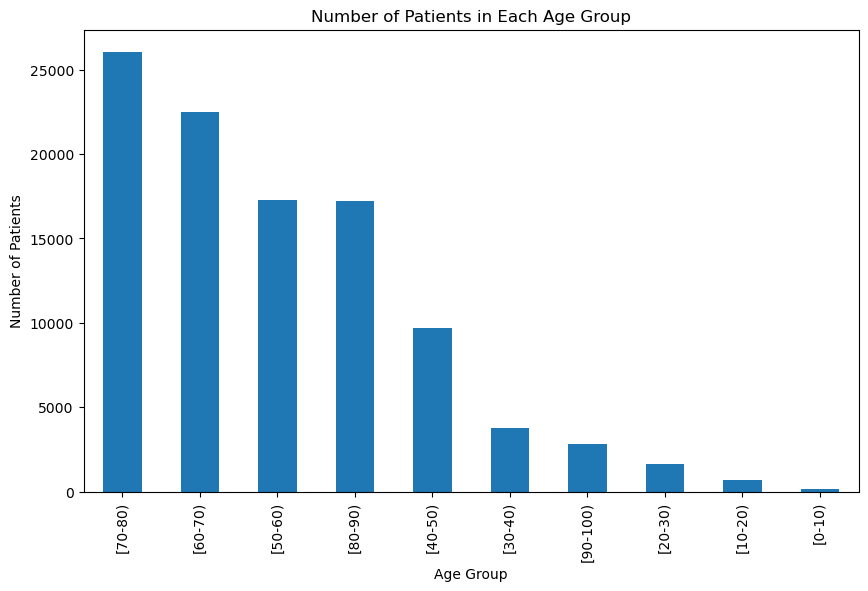

In [18]:
# # # A bar chart to show the number of patients in each age group

import matplotlib.pyplot as plt

age_count = df['age'].value_counts()
age_count.plot(kind='bar',figsize=(10, 6))
plt.title('Number of Patients in Each Age Group')
plt.xlabel('Age Group')
plt.ylabel('Number of Patients')
plt.show()


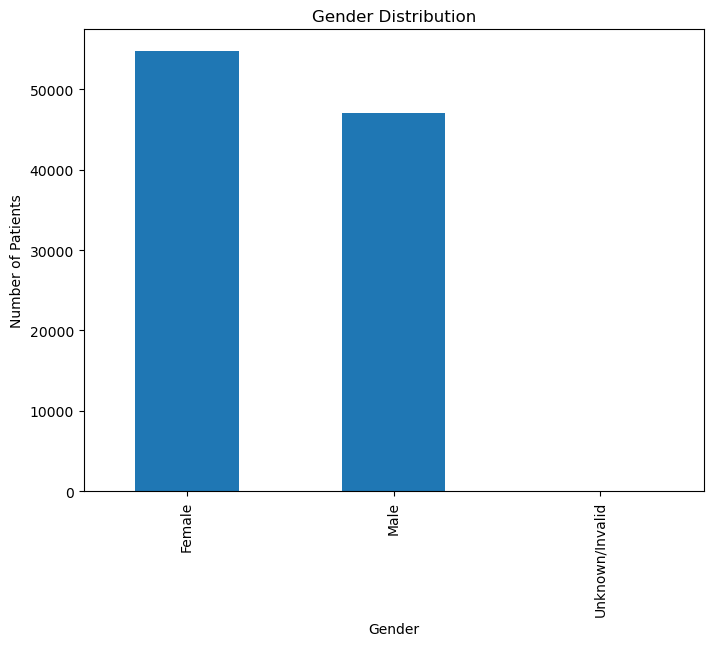

In [19]:
# # # Show the gender distribution

import matplotlib.pyplot as plt

gender_counts = df['gender'].value_counts()

gender_counts.plot(kind='bar',figsize=(8, 6))
plt.title('Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Number of Patients')
plt.show()


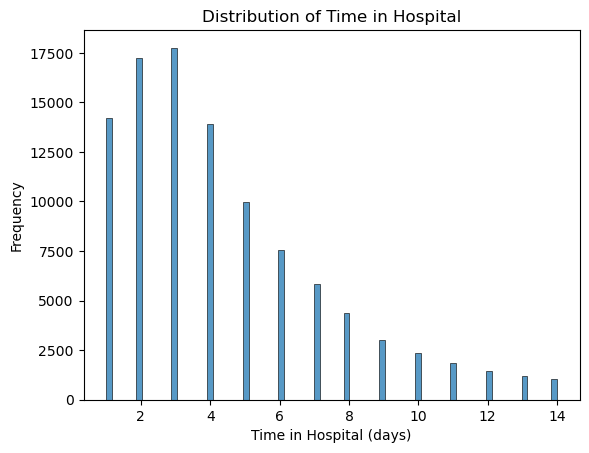

In [20]:
# # # Show the time_in_hospital distribution

import matplotlib.pyplot as plt
import seaborn as sns
sns.histplot(df['time_in_hospital'])
plt.title('Distribution of Time in Hospital')
plt.xlabel('Time in Hospital (days)')
plt.ylabel('Frequency')
plt.show()

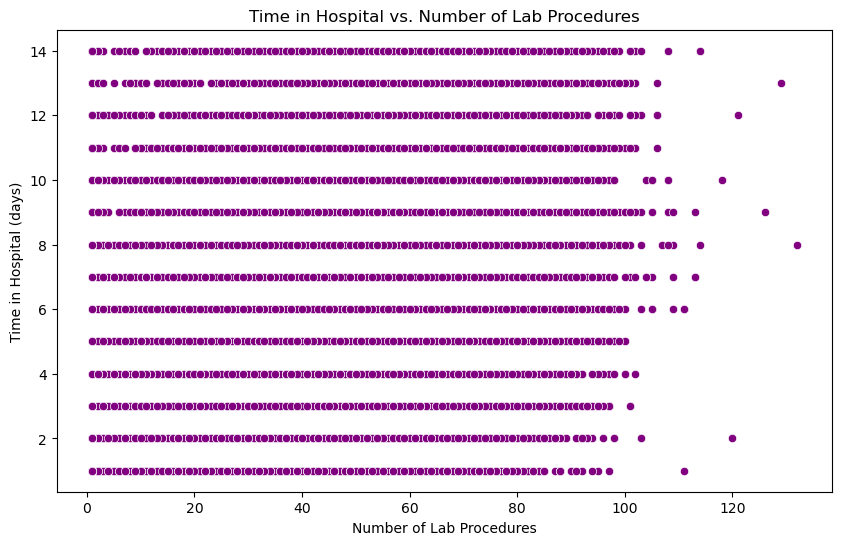

In [21]:
# # # Scatter plot for time_in_hospital vs. num_lab_procedures
import seaborn as sns
plt.figure(figsize=(10, 6))
sns.scatterplot(x='num_lab_procedures', y='time_in_hospital', data=df, color='purple')
plt.title('Time in Hospital vs. Number of Lab Procedures')
plt.xlabel('Number of Lab Procedures')
plt.ylabel('Time in Hospital (days)')
plt.show()




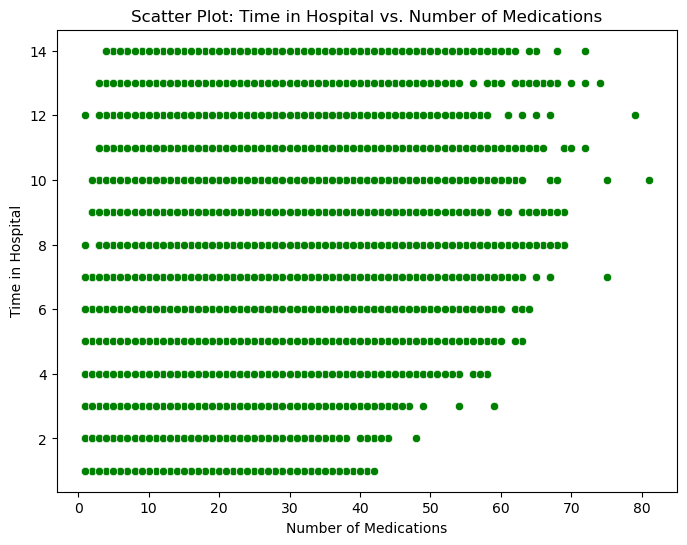

In [22]:
# # # Scatter plots to show the relationship between time_in_hospital and other features

plt.figure(figsize=(8, 6))
sns.scatterplot(x='num_medications', y='time_in_hospital', data=df, color='green')
plt.title('Scatter Plot: Time in Hospital vs. Number of Medications')
plt.xlabel('Number of Medications')
plt.ylabel('Time in Hospital')
plt.show()

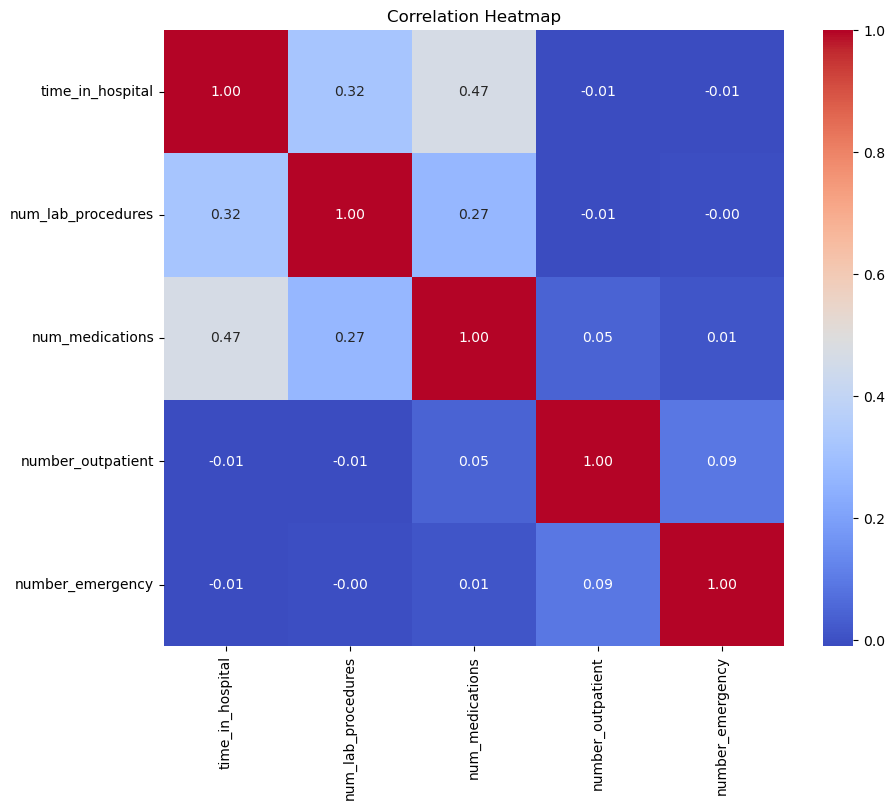

In [23]:
# # # Correlation heatmap with time in hospital 

plt.figure(figsize=(10, 8))
corr = df[['time_in_hospital', 'num_lab_procedures', 'num_medications', 'number_outpatient', 'number_emergency']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

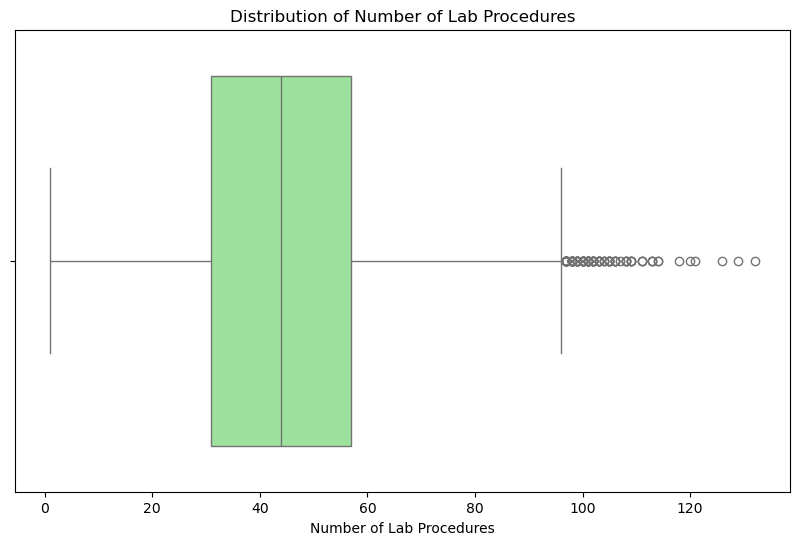

In [24]:
# # #  distribution of num_lab_procedures
import seaborn as sns
import matplotlib.pyplot as plt

df['num_lab_procedures'] = pd.to_numeric(df['num_lab_procedures'], )

plt.figure(figsize=(10,6))
sns.boxplot(x=df['num_lab_procedures'], color='lightgreen')
plt.title('Distribution of Number of Lab Procedures')
plt.xlabel('Number of Lab Procedures')
plt.show()


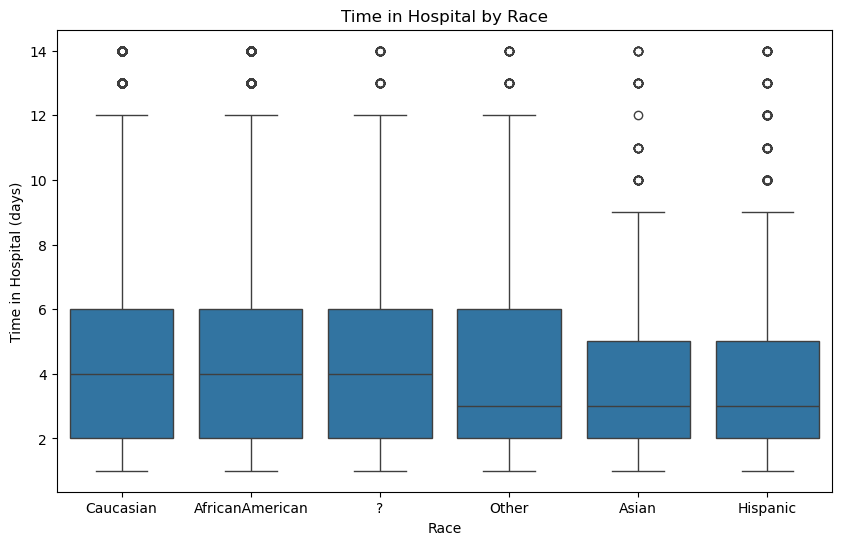

In [25]:
# # # Boxplot for time_in_hospital by race

plt.figure(figsize=(10, 6))
sns.boxplot(x='race', y='time_in_hospital', data=df)
plt.title('Time in Hospital by Race')
plt.xlabel('Race')
plt.ylabel('Time in Hospital (days)')
plt.show()

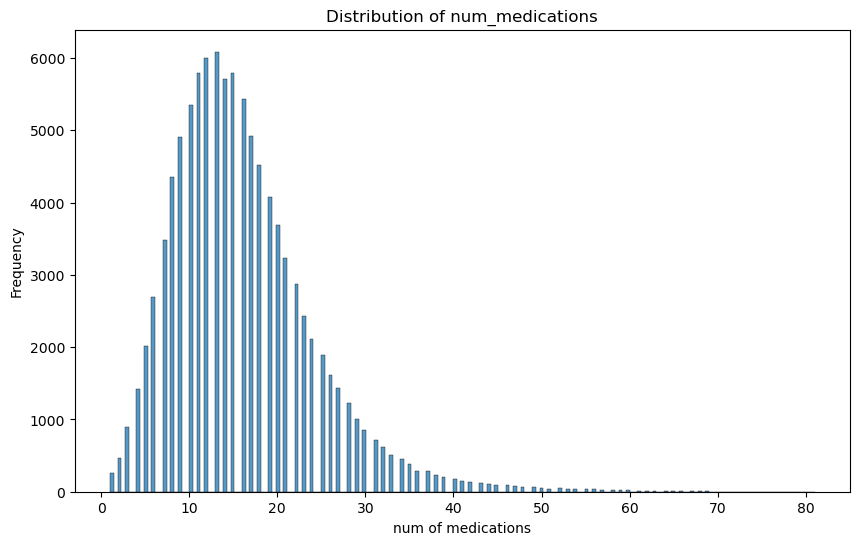

In [26]:
# # # distribution of num_medications

import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
sns.histplot(df['num_medications'])
plt.title('Distribution of num_medications')
plt.xlabel('num of medications')
plt.ylabel('Frequency')
plt.show()

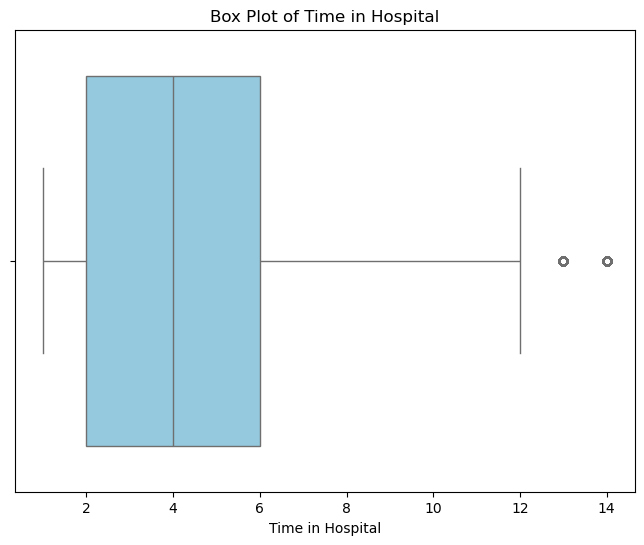

In [27]:
# # # visualizing  outliers in the time_in_hospital

import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(8, 6))
sns.boxplot(x='time_in_hospital', data=df, color='skyblue')
plt.title('Box Plot of Time in Hospital')
plt.xlabel('Time in Hospital')
plt.show()


### 1B.5 Identify Metadata from the Dataset

In [28]:
import pandas as pd
import numpy as np

# Column names
print("Column Names:")
print(df.columns)

# Data types
print("\nData Types:")
print(df.dtypes)

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Unique values for categorical columns
print("\nUnique Values:")
print(df.nunique())

# Basic statistics for numerical columns
print("\nStatistics:")
print(df.describe())

# Shape of the dataset
print("\nShape of the Dataset:")
print(df.shape)


Column Names:
Index(['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight',
       'admission_type_id', 'discharge_disposition_id', 'admission_source_id',
       'time_in_hospital', 'payer_code', 'medical_specialty',
       'num_lab_procedures', 'num_procedures', 'num_medications',
       'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1',
       'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult',
       'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
       'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
       'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
       'tolazamide', 'examide', 'citoglipton', 'insulin',
       'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted'],
      dtype='object')

Data Types:
encounter_id                 int64
patient

### 1B.6 Splitting Data for Analysis

In [29]:
# split datase to train, test and validation set.
from sklearn.model_selection import train_test_split
X=df.drop(columns=['time_in_hospital'])
y=df['time_in_hospital']

X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.2, random_state=42)



_________
## *Task 2: Data Processing
### Task Description
Create a robust data preprocessing pipeline to handle missing values, encode categorical variables, and scale numerical features.

### **Task 2.1: Initial Cleaning and Pre-processing**

#### 2.1.1: Load and Visualise the Data
- Use pandas to load the dataset.
- Visualise the first few rows to understand the structure of the data.

# Loading the data

In [30]:
# # #  Loading the data


import pandas as pd
mydata=pd.read_csv("data/diabetic_data.csv")

# # #  Display first few rows

mydata.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


#### 2.1.2: Display Data Types and Check for Incorrect Types

- Use the .dtypes attribute to display each column's data type.
- Identify columns that have unexpected data types (e.g., numeric data stored as strings).

In [31]:
# # #  Display data types of each column
print('data types of each column:', mydata.dtypes)

data types of each column: encounter_id                 int64
patient_nbr                  int64
race                        object
gender                      object
age                         object
weight                      object
admission_type_id            int64
discharge_disposition_id     int64
admission_source_id          int64
time_in_hospital             int64
payer_code                  object
medical_specialty           object
num_lab_procedures           int64
num_procedures               int64
num_medications              int64
number_outpatient            int64
number_emergency             int64
number_inpatient             int64
diag_1                      object
diag_2                      object
diag_3                      object
number_diagnoses             int64
max_glu_serum               object
A1Cresult                   object
metformin                   object
repaglinide                 object
nateglinide                 object
chlorpropamide              

#### 2.1.3: Identify and Remove Duplicate Rows

- Check for duplicate rows.
- If duplicates exist, remove them 

In [32]:
# # # Identify and Remove Duplicate Rows

duplicate_rows=mydata.duplicated()
print(f"number of duplicate rows",{duplicate_rows.sum()})

number of duplicate rows {0}


### Task 2.2: Handling Metadata and Missing Values
#### 2.2.1: Identify Metadata from the Dataset
Metadata includes information like column names, data types, and any additional descriptive information.

In [33]:
# # #  Display metadata including column names and data types

# Column names
print("Column Names:")
print(mydata.columns.tolist())

# Data types
print("\nData Types:")
print(mydata.dtypes)

# Missing values
print("\nMissing Values:")
print(mydata.isnull().sum())

# Unique values for categorical columns
print("\nUnique Values:")
print(mydata.nunique())

# statistics for numerical columns
print("\nStatistics:")
print(mydata.describe())

# Shape of the dataset
print("\nShape of the Dataset:")
print(mydata.shape)

Column Names:
['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'payer_code', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted']

Data Types:
encounter_id                 int64
patient_nbr                  int64
race                        object
gender                      object
age            


#### 2.2.2: Analyse Different Types of Data
- Categorize columns based on their data types (e.g., numerical, categorical).
- Describe the significance of each data type and how it might impact data processing.

In [34]:
# # # Describe data to understand different types
import pandas as pd

data_types = mydata.dtypes

# # # Categorize columns based on their data types
numerical_data = mydata.select_dtypes(include=['number']).columns
categorical_data = mydata.select_dtypes(include=['object']).columns
boolean_data = mydata.select_dtypes(include=['bool']).columns
datetime_data = mydata.select_dtypes(include=['datetime']).columns

# # # Display the categorized data types
print("Numerical Data Columns:")
print(numerical_data)

print("\nCategorical Data Columns:")
print(categorical_data)

print("\nBoolean Data Columns:")
print(boolean_data)

print("\nDatetime Data Columns:")
print(datetime_data)



Numerical Data Columns:
Index(['encounter_id', 'patient_nbr', 'admission_type_id',
       'discharge_disposition_id', 'admission_source_id', 'time_in_hospital',
       'num_lab_procedures', 'num_procedures', 'num_medications',
       'number_outpatient', 'number_emergency', 'number_inpatient',
       'number_diagnoses'],
      dtype='object')

Categorical Data Columns:
Index(['race', 'gender', 'age', 'weight', 'payer_code', 'medical_specialty',
       'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult', 'metformin',
       'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride',
       'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
       'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
       'tolazamide', 'examide', 'citoglipton', 'insulin',
       'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted'],
      dtyp

#### 2.2.3: Identify Missing Values
- Missing values can significantly impact model performance and analysis.
- Count missing values in each column.
- Calculate the percentage of missing values.

In [35]:
# Identify and calculate the percentage of missing values
 #<add your code here>

missing_values = mydata.isnull().sum()

# # # Calculating  the percentage of missing values in each column
missing_percentage = (missing_values / len(mydata)) * 100

# # # Create a DataFrame to show the missing values and their percentage
missing_data = pd.DataFrame({'Missing Values': missing_values, 'Percentage': missing_percentage})

missing_data = missing_data[missing_data['Missing Values'] > 0]
print(missing_data)


               Missing Values  Percentage
max_glu_serum           96420   94.746772
A1Cresult               84748   83.277322


In [36]:
# Dropping the columns with high percentage of missing values
mydata.drop(['max_glu_serum', 'A1Cresult'], axis=1, inplace=True)


In [37]:
# # # Counting the '?' per column

Counting_question_mark= (mydata== '?').sum()
print("Occurrences of '?' per column:") 
print(Counting_question_mark)

Occurrences of '?' per column:
encounter_id                    0
patient_nbr                     0
race                         2273
gender                          0
age                             0
weight                      98569
admission_type_id               0
discharge_disposition_id        0
admission_source_id             0
time_in_hospital                0
payer_code                  40256
medical_specialty           49949
num_lab_procedures              0
num_procedures                  0
num_medications                 0
number_outpatient               0
number_emergency                0
number_inpatient                0
diag_1                         21
diag_2                        358
diag_3                       1423
number_diagnoses                0
metformin                       0
repaglinide                     0
nateglinide                     0
chlorpropamide                  0
glimepiride                     0
acetohexamide                   0
glipizide        

In [38]:
# # # dropping columns with high missing values & not needed 
mydata.drop(['weight', 'payer_code', 'medical_specialty','encounter_id','patient_nbr','examide','citoglipton'], axis=1, inplace=True)


In [39]:
# Replacing '?' with the mode in columns with '?' occurrences

columns_to_replace = ['race', 'diag_1', 'diag_2', 'diag_3']
for col in columns_to_replace:
    mydata[col] = mydata[col].replace('?', mydata[col].mode()[0])

In [40]:
# # # counting ? after cleaning 
Counting_question_mark= (mydata == '?').sum()
Counting_question_mark

race                        0
gender                      0
age                         0
admission_type_id           0
discharge_disposition_id    0
admission_source_id         0
time_in_hospital            0
num_lab_procedures          0
num_procedures              0
num_medications             0
number_outpatient           0
number_emergency            0
number_inpatient            0
diag_1                      0
diag_2                      0
diag_3                      0
number_diagnoses            0
metformin                   0
repaglinide                 0
nateglinide                 0
chlorpropamide              0
glimepiride                 0
acetohexamide               0
glipizide                   0
glyburide                   0
tolbutamide                 0
pioglitazone                0
rosiglitazone               0
acarbose                    0
miglitol                    0
troglitazone                0
tolazamide                  0
insulin                     0
glyburide-

# Feature Engineering

In [41]:
# # # Mapping
medication_mapping_normal = {
    'Yes': 1, 
    'No': 0, 
    'Steady': 1, 
    'Up': 2, 
    'Down': 3, 
    'Ch': 4
}


medication_columns = [
    'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 
    'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 
    'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 
    'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 
    'metformin-rosiglitazone', 'metformin-pioglitazone'
]

# # # Applying the mapping to all medication columns
for column in medication_columns:
    mydata[column] = mydata[column].map(medication_mapping_normal)



# # # mapping change to 1 and 0 
mydata['change'] = mydata['change'].map({'No': 0, 'Ch': 1}).fillna(0)

# # # mapping diabetesMed 
mydata['diabetesMed'] = mydata['diabetesMed'].map({'Yes': 1, 'No': 0})

# # # mapping insulin
mydata['insulin'] = mydata['insulin'].map({'No': 0, 'Up': 2, 'Steady': 1, 'Down': 3})

# # #  Mapping  'readmitted' to distinct values
mydata['readmitted'] = mydata['readmitted'].map({'NO': 0, '>30': 2, '<30': 3})



print(mydata[['change', 'diabetesMed', 'readmitted', 'insulin', 'metformin',
    'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 
    'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 
    'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 
    'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 
    'metformin-rosiglitazone', 'metformin-pioglitazone']].head(50))


    change  diabetesMed  readmitted  insulin  metformin  repaglinide  \
0        0            0           0        0          0            0   
1        1            1           2        2          0            0   
2        0            1           0        0          0            0   
3        1            1           0        2          0            0   
4        1            1           0        1          0            0   
5        0            1           2        1          0            0   
6        1            1           0        1          1            0   
7        0            1           2        0          0            0   
8        1            1           0        1          0            0   
9        1            1           0        1          0            0   
10       0            1           2        1          0            0   
11       1            1           3        1          0            0   
12       1            1           3        3          1         

In [42]:
# # # Mapping Categorical Values to Numeric Values:
mydata['gender'] = mydata['gender'].map({'Male': 1, 'Female': 0, 'Unknown/Invalid': 2})


In [43]:
# # # mapping  diag 1  , diag 2 , diag 3
diagnosis_mapping = {
    '250.83': 'Diabetes',
    '276': 'Fluid Disorders',
    '648': 'Pregnancy-Related',
    '8': 'Infectious Diseases',
    '197': 'Neoplasms',
    '414': 'Heart Disease',
    '428': 'Heart Failure',
    '398': 'Heart Valve Disorders',
    '434': 'Cerebrovascular Disease',
    '427': 'Cardiac Dysrhythmias',
    '518': 'Respiratory Failure',
    '786': 'Respiratory Symptoms',
    '996': 'Injury or Complication',
    'V57': 'Supplementary',
    'V45': 'Supplementary',
    '?': 'Unknown',
    '255': 'Endocrine Disorders',
    '403': 'Hypertensive Kidney Disease',
    '250.01': 'Diabetes',
    '250.43': 'Diabetes',
    'V27': 'Supplementary'
   
}

# Apply the mapping to each diagnosis column
mydata['diag_1_mapped'] = mydata['diag_1'].map(diagnosis_mapping).fillna('Other')
mydata['diag_2_mapped'] = mydata['diag_2'].map(diagnosis_mapping).fillna('Other')
mydata['diag_3_mapped'] = mydata['diag_3'].map(diagnosis_mapping).fillna('Other')
# Display the first few rows of the relevant columns
print(mydata[['diag_1', 'diag_1_mapped', 'diag_2', 'diag_2_mapped', 'diag_3', 'diag_3_mapped']].head())


   diag_1        diag_1_mapped  diag_2    diag_2_mapped diag_3  \
0  250.83             Diabetes     276  Fluid Disorders    250   
1     276      Fluid Disorders  250.01         Diabetes    255   
2     648    Pregnancy-Related     250            Other    V27   
3       8  Infectious Diseases  250.43         Diabetes    403   
4     197            Neoplasms     157            Other    250   

                 diag_3_mapped  
0                        Other  
1          Endocrine Disorders  
2                Supplementary  
3  Hypertensive Kidney Disease  
4                        Other  


In [44]:
# # # encdoing diag 1 , diag2 , diag 3 
from sklearn.preprocessing import LabelEncoder

# Initialize the LabelEncoder
le = LabelEncoder()

# Apply LabelEncoder to each column
mydata['diag_1'] = le.fit_transform(mydata['diag_1_mapped'])
mydata['diag_2'] = le.fit_transform(mydata['diag_2_mapped'])
mydata['diag_3'] = le.fit_transform(mydata['diag_3_mapped'])

# Display the encoded columns
print(mydata[[ 'diag_1',  'diag_2',  'diag_3']])
mydata = mydata.drop(['diag_1_mapped', 'diag_2_mapped', 'diag_3_mapped'], axis=1)





        diag_1  diag_2  diag_3
0            2       4      12
1            4       2       3
2           13      12      16
3            9       2       8
4           11      12      12
...        ...     ...     ...
101761      12      12      12
101762      12       4      12
101763      12      12      12
101764      10      12      12
101765      12      12      12

[101766 rows x 3 columns]


In [ ]:
# # #  mapping admission_type_mapping , discharge_disposition_mapping , admission_source_mapping
admission_type_mapping = {
    1: 'Emergency',
    2: 'Urgent',
    3: 'Elective',
    4: 'Newborn',
    5: 'Not Available',
    6: 'NULL',
    7: 'Trauma Center',
    8: 'Not Mapped'
}

discharge_disposition_mapping = {
    1: 'Discharged to home',
    2: 'Discharged/transferred to another short term hospital',
    3: 'Discharged/transferred to SNF',
    4: 'Discharged/transferred to ICF',
    5: 'Discharged/transferred to another type of inpatient care institution',
    6: 'Discharged/transferred to home with home health service',
    7: 'Left AMA',
    8: 'Discharged/transferred to home under care of Home IV provider',
    9: 'Admitted as an inpatient to this hospital',
    10: 'Neonate discharged to another hospital for neonatal aftercare',
    11: 'Expired',
    12: 'Still patient or expected to return for outpatient services',
    13: 'Hospice / home',
    14: 'Hospice / medical facility',
    15: 'Discharged/transferred within this institution to Medicare approved swing bed',
    16: 'Discharged/transferred/referred another institution for outpatient services',
    17: 'Discharged/transferred/referred to this institution for outpatient services',
    18: 'NULL',
    19: 'Expired at home. Medicaid only, hospice.',
    20: 'Expired in a medical facility. Medicaid only, hospice.',
    21: 'Expired, place unknown. Medicaid only, hospice.',
    22: 'Discharged/transferred to another rehab fac including rehab units of a hospital.',
    23: 'Discharged/transferred to a long term care hospital.',
    24: 'Discharged/transferred to a nursing facility certified under Medicaid but not certified under Medicare.',
    25: 'Not Mapped',
    26: 'Unknown/Invalid',
    27: 'Discharged/transferred to a federal health care facility.',
    28: 'Discharged/transferred/referred to a psychiatric hospital of psychiatric distinct part unit of a hospital',
    29: 'Discharged/transferred to a Critical Access Hospital (CAH).',
    30: 'Discharged/transferred to another Type of Health Care Institution not Defined Elsewhere'
}

admission_source_mapping = {
    1: 'Physician Referral',
    2: 'Clinic Referral',
    3: 'HMO Referral',
    4: 'Transfer from a hospital',
    5: 'Transfer from a Skilled Nursing Facility (SNF)',
    6: 'Transfer from another health care facility',
    7: 'Emergency Room',
    8: 'Court/Law Enforcement',
    9: 'Not Available',
    10: 'Transfer from critical access hospital',
    11: 'Normal Delivery',
    12: 'Premature Delivery',
    13: 'Sick Baby',
    14: 'Extramural Birth',
    15: 'Not Available',
    17: 'NULL',
    18: 'Transfer From Another Home Health Agency',
    19: 'Readmission to Same Home Health Agency',
    20: 'Not Mapped',
    21: 'Unknown/Invalid',
    22: 'Transfer from hospital inpt/same fac reslt in a sep claim',
    23: 'Born inside this hospital',
    24: 'Born outside this hospital',
    25: 'Transfer from Ambulatory Surgery Center',
    26: 'Transfer from Hospice'
}

# Map the IDs to descriptions
mydata['admission_type_mapped'] = mydata['admission_type_id'].map(admission_type_mapping).fillna('Other')
mydata['discharge_disposition_mapped'] = mydata['discharge_disposition_id'].map(discharge_disposition_mapping).fillna('Unkown')
mydata['admission_source_mapped'] = mydata['admission_source_id'].map(admission_source_mapping).fillna('Other')

print(mydata[['admission_type_id', 'admission_type_mapped', 
              'discharge_disposition_id', 'discharge_disposition_mapped', 
              'admission_source_id', 'admission_source_mapped']].head())




   admission_type_id admission_type_mapped  discharge_disposition_id  \
0                  6                  NULL                        25   
1                  1             Emergency                         1   
2                  1             Emergency                         1   
3                  1             Emergency                         1   
4                  1             Emergency                         1   

  discharge_disposition_mapped  admission_source_id admission_source_mapped  
0                   Not Mapped                    1      Physician Referral  
1           Discharged to home                    7          Emergency Room  
2           Discharged to home                    7          Emergency Room  
3           Discharged to home                    7          Emergency Room  
4           Discharged to home                    7          Emergency Room  


In [46]:
# # # encoding  admission_type_mapping , discharge_disposition_mapping , admission_source_mapping
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()


mydata['admission_type_id'] = le.fit_transform(mydata['admission_type_mapped'])
mydata['discharge_disposition_id'] = le.fit_transform(mydata['discharge_disposition_mapped'])
mydata['admission_source_id'] = le.fit_transform(mydata['admission_source_mapped'])

# # #  Dropping the original mapping columns as they are now encoded
mydata = mydata.drop(['admission_type_mapped', 'discharge_disposition_mapped', 'admission_source_mapped'], axis=1)
print(mydata[['admission_type_id', 'discharge_disposition_id', 'admission_source_id']].head(10))



   admission_type_id  discharge_disposition_id  admission_source_id
0                  2                        24                    9
1                  1                         1                    2
2                  1                         1                    2
3                  1                         1                    2
4                  1                         1                    2
5                  7                         1                    0
6                  0                         1                    0
7                  1                         1                    2
8                  7                         1                   13
9                  0                         3                   13


In [47]:
# # # one-hot encoding to the 'race' and age column 
mydata= pd.get_dummies(mydata, columns=['race','age'], drop_first=True)

In [48]:

print(mydata.dtypes)

gender                      int64
admission_type_id           int32
discharge_disposition_id    int32
admission_source_id         int32
time_in_hospital            int64
num_lab_procedures          int64
num_procedures              int64
num_medications             int64
number_outpatient           int64
number_emergency            int64
number_inpatient            int64
diag_1                      int32
diag_2                      int32
diag_3                      int32
number_diagnoses            int64
metformin                   int64
repaglinide                 int64
nateglinide                 int64
chlorpropamide              int64
glimepiride                 int64
acetohexamide               int64
glipizide                   int64
glyburide                   int64
tolbutamide                 int64
pioglitazone                int64
rosiglitazone               int64
acarbose                    int64
miglitol                    int64
troglitazone                int64
tolazamide    

In [49]:
# # #  Converting  all boolean columns to integers (1 for True, 0 for False)
mydata[mydata.select_dtypes(include='bool').columns] = mydata.select_dtypes(include='bool').astype(int)

In [50]:
# # # printing head to see after conversion
mydata.head()

,gender,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,...,race_Other,age_[10-20),age_[20-30),age_[30-40),age_[40-50),age_[50-60),age_[60-70),age_[70-80),age_[80-90),age_[90-100)
0,0,2,24,9,1,41,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,1,1,2,3,59,0,18,0,0,...,0,1,0,0,0,0,0,0,0,0
2,0,1,1,2,2,11,5,13,2,0,...,0,0,1,0,0,0,0,0,0,0
3,1,1,1,2,2,44,1,16,0,0,...,0,0,0,1,0,0,0,0,0,0
4,1,1,1,2,1,51,0,8,0,0,...,0,0,0,0,1,0,0,0,0,0


In [51]:
# # # Chicking data 

mydata.dtypes
mydata.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 52 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   gender                    101766 non-null  int64
 1   admission_type_id         101766 non-null  int32
 2   discharge_disposition_id  101766 non-null  int32
 3   admission_source_id       101766 non-null  int32
 4   time_in_hospital          101766 non-null  int64
 5   num_lab_procedures        101766 non-null  int64
 6   num_procedures            101766 non-null  int64
 7   num_medications           101766 non-null  int64
 8   number_outpatient         101766 non-null  int64
 9   number_emergency          101766 non-null  int64
 10  number_inpatient          101766 non-null  int64
 11  diag_1                    101766 non-null  int32
 12  diag_2                    101766 non-null  int32
 13  diag_3                    101766 non-null  int32
 14  number_diagnoses    

In [52]:
# # # saving mydata as cleaned data 

cleaned_data = mydata
cleaned_data.to_csv('data/cleaned_data.csv', index=False)
cleaned_data.head()


,gender,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,...,race_Other,age_[10-20),age_[20-30),age_[30-40),age_[40-50),age_[50-60),age_[60-70),age_[70-80),age_[80-90),age_[90-100)
0,0,2,24,9,1,41,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,1,1,2,3,59,0,18,0,0,...,0,1,0,0,0,0,0,0,0,0
2,0,1,1,2,2,11,5,13,2,0,...,0,0,1,0,0,0,0,0,0,0
3,1,1,1,2,2,44,1,16,0,0,...,0,0,0,1,0,0,0,0,0,0
4,1,1,1,2,1,51,0,8,0,0,...,0,0,0,0,1,0,0,0,0,0


In [53]:
# # # checking data types
cleaned_data.dtypes

gender                      int64
admission_type_id           int32
discharge_disposition_id    int32
admission_source_id         int32
time_in_hospital            int64
num_lab_procedures          int64
num_procedures              int64
num_medications             int64
number_outpatient           int64
number_emergency            int64
number_inpatient            int64
diag_1                      int32
diag_2                      int32
diag_3                      int32
number_diagnoses            int64
metformin                   int64
repaglinide                 int64
nateglinide                 int64
chlorpropamide              int64
glimepiride                 int64
acetohexamide               int64
glipizide                   int64
glyburide                   int64
tolbutamide                 int64
pioglitazone                int64
rosiglitazone               int64
acarbose                    int64
miglitol                    int64
troglitazone                int64
tolazamide    

In [54]:
# # # checking for any missing value.

cleaned_data.isnull().sum()

gender                      0
admission_type_id           0
discharge_disposition_id    0
admission_source_id         0
time_in_hospital            0
num_lab_procedures          0
num_procedures              0
num_medications             0
number_outpatient           0
number_emergency            0
number_inpatient            0
diag_1                      0
diag_2                      0
diag_3                      0
number_diagnoses            0
metformin                   0
repaglinide                 0
nateglinide                 0
chlorpropamide              0
glimepiride                 0
acetohexamide               0
glipizide                   0
glyburide                   0
tolbutamide                 0
pioglitazone                0
rosiglitazone               0
acarbose                    0
miglitol                    0
troglitazone                0
tolazamide                  0
insulin                     0
glyburide-metformin         0
glipizide-metformin         0
glimepirid

___________
## *Task 3: Machine Learning
### Task Description
Implement various machine learning algorithms for regression, classification and clustering and evaluating them.

### **Task 3.1: Implementing Regression Baseline**
#### 3.1.1: Loading the data
- Use pandas to load the dataset.

In [55]:
import pandas as pd
# # # loading the data for ML
data = pd.read_csv('data/cleaned_data.csv')
data.head()

,gender,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,...,race_Other,age_[10-20),age_[20-30),age_[30-40),age_[40-50),age_[50-60),age_[60-70),age_[70-80),age_[80-90),age_[90-100)
0,0,2,24,9,1,41,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,1,1,2,3,59,0,18,0,0,...,0,1,0,0,0,0,0,0,0,0
2,0,1,1,2,2,11,5,13,2,0,...,0,0,1,0,0,0,0,0,0,0
3,1,1,1,2,2,44,1,16,0,0,...,0,0,0,1,0,0,0,0,0,0
4,1,1,1,2,1,51,0,8,0,0,...,0,0,0,0,1,0,0,0,0,0


In [56]:
# # #  correlation matrix 
correlation_matrix = data.corr()
print(correlation_matrix['time_in_hospital'].sort_values(ascending=False))


time_in_hospital            1.000000
num_medications             0.466135
num_lab_procedures          0.318450
number_diagnoses            0.220186
num_procedures              0.191472
discharge_disposition_id    0.154386
insulin                     0.120577
change                      0.109173
number_inpatient            0.073623
diabetesMed                 0.062520
age_[80-90)                 0.062336
readmitted                  0.056327
diag_1                      0.055098
glyburide                   0.042523
age_[70-80)                 0.038313
repaglinide                 0.037829
glipizide                   0.036928
glimepiride                 0.027652
admission_source_id         0.025562
admission_type_id           0.024282
age_[90-100)                0.020250
pioglitazone                0.015307
rosiglitazone               0.012705
acetohexamide               0.010085
diag_2                      0.009583
metformin                   0.007128
nateglinide                 0.007043
a

Splitting data ensures that models are trained on one portion of the data and tested on another, unseen portion.

In [57]:
from sklearn.model_selection import train_test_split
import pandas as pd
# Features and target
X = data[['num_medications', 'num_lab_procedures', 'number_diagnoses', 'num_procedures', 'insulin','change','discharge_disposition_id']]

y = data['time_in_hospital']

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

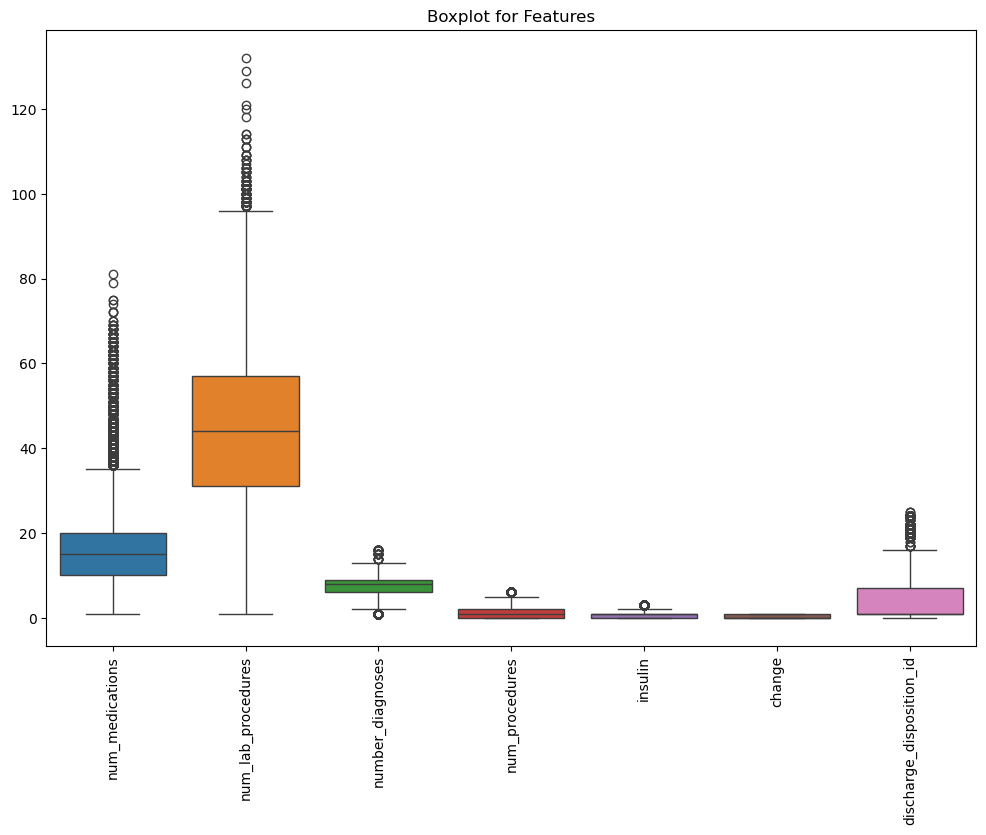

In [58]:
# # # checking for outliers 
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))
sns.boxplot(data=X,) 
plt.xticks(rotation=90)  
plt.title("Boxplot for Features")
plt.show()

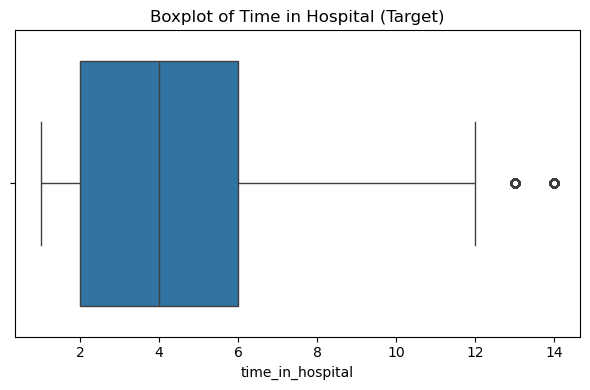

In [59]:
# Plot boxplot for the target variable (time_in_hospital)
plt.figure(figsize=(6, 4))
sns.boxplot(x=y)
plt.title('Boxplot of Time in Hospital (Target)')
plt.tight_layout()
plt.show()


In [60]:
### scaling the nuerical coulmns
from sklearn.preprocessing import StandardScaler
numerical_columns = ['num_medications', 'number_diagnoses', 'num_procedures']
scaler = StandardScaler()
X_train[numerical_columns] = scaler.fit_transform(X_train[numerical_columns])

X_test[numerical_columns] = scaler.transform(X_test[numerical_columns])

print(X_train[numerical_columns].head())

       num_medications  number_diagnoses  num_procedures
24079        -0.616845          0.815991       -0.784879
98079        -1.355826         -0.735143       -0.784879
6237         -0.740008         -0.218099       -0.784879
72208        -0.986336          0.298946       -0.784879
33075         0.861118          0.298946        0.974798


#### 3.1.2: Start to implement Linear Regression as a baseline model

In [61]:
X_train

,num_medications,num_lab_procedures,number_diagnoses,num_procedures,insulin,change,discharge_disposition_id
24079,-0.616845,48,0.815991,-0.784879,0,0,1
98079,-1.355826,42,-0.735143,-0.784879,0,0,1
6237,-0.740008,44,-0.218099,-0.784879,0,0,1
72208,-0.986336,54,0.298946,-0.784879,1,1,3
33075,0.861118,35,0.298946,0.974798,0,0,16
...,...,...,...,...,...,...,...
6265,-0.493681,35,0.815991,-0.784879,0,0,1
54886,0.861118,63,0.815991,0.388239,2,1,1
76820,2.092753,55,0.815991,-0.198320,3,1,3
860,0.614790,77,0.815991,0.388239,3,1,24


In [62]:
# # # importing requires sklearn packages for implementing linear regression
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error , mean_absolute_error
import numpy as np
from sklearn.model_selection import cross_val_score ,KFold
# # # Initialising and training Linear Regression model
linear_model = LinearRegression()
# # # doing cross val 
kf = KFold(n_splits=6, shuffle=True, random_state=42)
cv_scores_mae = -cross_val_score(linear_model, X, y, cv=kf, scoring='neg_mean_absolute_error')

# # # fitting the model
linear_model.fit(X_train, y_train)
# # # Predictions

y_pred_linear = linear_model.predict(X_test)

# # # Evaluation

mae_linear = mean_absolute_error(y_test, y_pred_linear)
mse_linear = mean_squared_error(y_test, y_pred_linear)
rmse_linear = np.sqrt(mse_linear)


print(f'Linear Regression RMSE:{rmse_linear}')
print(f"Linear Regression MAE: {mae_linear}")
print(f"Linear Regression MSE: {mse_linear}")
print(f"Cross-Validation MAE Scores: {cv_scores_mae}")


Linear Regression RMSE:2.51450808321564
Linear Regression MAE: 1.917395090082134
Linear Regression MSE: 6.322750900556791
Cross-Validation MAE Scores: [1.91519806 1.95011137 1.92159999 1.92832801 1.93223313 1.93341281]


# Using ridge 

In [63]:
from sklearn.linear_model import Ridge

scores = []
for alpha in [1.0, 10.0, 20.0, 50.0]:
    ridge = Ridge(alpha=alpha)
    ridge.fit(X_train, y_train)
    y_pred = ridge.predict(X_test)
    scores.append(ridge.score(X_test, y_test))  # R^2 Score

print(scores)


[0.2735873475897377, 0.27358757213404417, 0.2735878168162087, 0.2735885205306846]


# Using lasso

In [64]:
from sklearn.linear_model import Lasso

scores = []
for alpha in [1.0, 10.0, 20.0, 50.0]:
    lasso = Lasso(alpha=alpha)
    lasso.fit(X_train, y_train)
    y_pred = lasso.predict(X_test)
    scores.append(lasso.score(X_test, y_test))  # R^2 Score

print(scores)


[0.15170388338387342, 0.07315434811649824, -8.771437309351704e-05, -8.771437309351704e-05]


#### 3.1.3: Visualise the output for linear regression

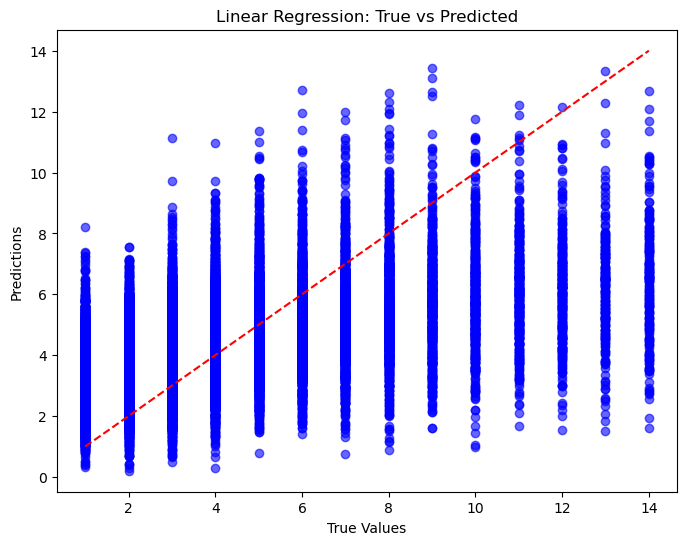

In [65]:
# # #  visualizing the output for Linear Regression
import matplotlib.pyplot as plt
y_pred_linear= linear_model.predict(X_test)
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_linear, color='blue', alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--') 
plt.xlabel('True Values')
plt.ylabel('Predictions')
plt.title('Linear Regression: True vs Predicted')
plt.show()

#### 3.1.4: Implement Decision Tree Regression for Non-linear Relationships

#### 3.1.5: Implement Gradient Boosting Regression

In [66]:
# Importing required libraries
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np
import pandas as pd
from sklearn.model_selection import cross_val_score ,KFold

# Define features (X) and target (y)
X = data[['num_medications', 'num_lab_procedures', 'number_diagnoses', 'num_procedures', 'insulin','change','discharge_disposition_id']]
y = data['time_in_hospital']

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


# Initialize and train the initial Decision Tree Regressor
tree_model = DecisionTreeRegressor(max_depth=10, min_samples_split=2, min_samples_leaf=20, random_state=42)
# # # doing cross val 
kf = KFold(n_splits=6, shuffle=True, random_state=42)
cv_scores_mae_dt = -cross_val_score(tree_model, X, y, cv=kf, scoring='neg_mean_absolute_error')
# # # fitting the model 

tree_model.fit(X_train, y_train)

# Make predictions and evaluate the initial model
y_pred_dt = tree_model.predict(X_test)
mae_dt = mean_absolute_error(y_test, y_pred_dt)
mse_dt = mean_squared_error(y_test, y_pred_dt)
rmse_dt = np.sqrt(mse_dt)

print(f"Initial Decision Tree Regression MAE: {mae_dt}")
print(f"Initial Decision Tree Regression MSE: {mse_dt}")
print(f'Initial Decision Tree Regression RMSE:{rmse_dt}')
print(f"Cross-Validation MAE Scores: {cv_scores_mae_dt}")


Initial Decision Tree Regression MAE: 1.8337687384882022
Initial Decision Tree Regression MSE: 5.9140793808711365
Initial Decision Tree Regression RMSE:2.4318880280290736
Cross-Validation MAE Scores: [1.83404322 1.86852322 1.838237   1.85525507 1.85163609 1.84988226]


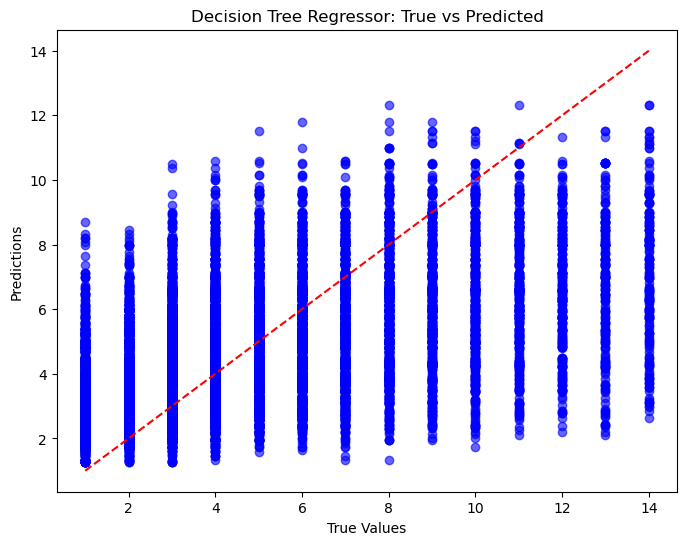

In [67]:
# # #  visualizing the output forDecision Tree Regressor model
import matplotlib.pyplot as plt
y_pred_dt = tree_model.predict(X_test)
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_dt, color='blue', alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--') 
plt.xlabel('True Values')
plt.ylabel('Predictions')
plt.title('Decision Tree Regressor: True vs Predicted')
plt.show()


In [68]:
# importing requires sklearn packages for implementing Gradient Boosting Regressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
from sklearn.model_selection import cross_val_score ,KFold
# Initialising and training Gradient Boosting Regressor
gboost_model = GradientBoostingRegressor( n_estimators=500, learning_rate=0.3)

# # # doing cros val
kf = KFold(n_splits=6, shuffle=True, random_state=42)
cv_scores_mae_gb = -cross_val_score(gboost_model, X, y, cv=kf, scoring='neg_mean_absolute_error')
# # # fitting the model
gboost_model.fit(X_train, y_train)

# Predictions
y_pred_gboost = gboost_model.predict(X_test)                          

# Evaluation
mae_gboost = mean_absolute_error(y_test,y_pred_gboost)
mse_gboost = mean_squared_error(y_test,y_pred_gboost)
rmse_gboost=np.sqrt(mse_gboost)


print(f"Gradient Boosting Regression MAE: {mae_gboost}")
print(f"Gradient Boosting Regression MSE: {mse_gboost}")
print(f"Gradient Boosting Regression RMSE:{rmse_gboost}")
print(f"Cross-Validation MAE Scores: {cv_scores_mae_gb}")

Gradient Boosting Regression MAE: 1.794062516865427
Gradient Boosting Regression MSE: 5.646100264651252
Gradient Boosting Regression RMSE:2.3761524077068903
Cross-Validation MAE Scores: [1.7908202  1.81999397 1.788742   1.80915791 1.80653464 1.79983126]


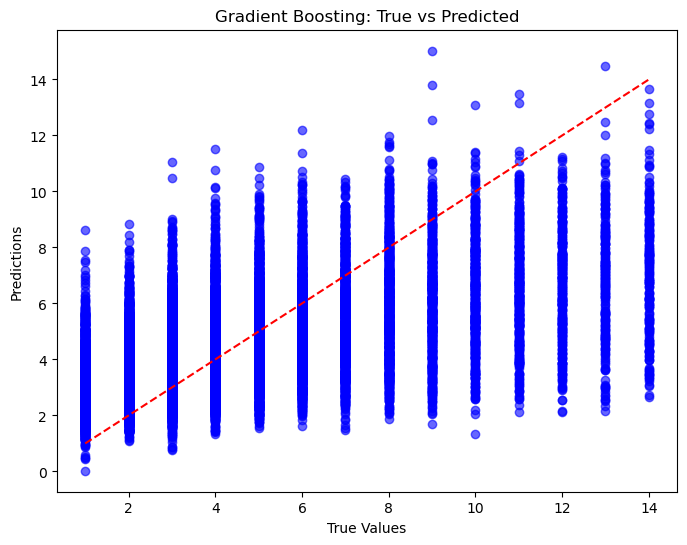

In [69]:
# # #  visualizing the output for Gradient Boosting Regression
import matplotlib.pyplot as plt
y_pred_gboost= gboost_model.predict(X_test)
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_gboost, color='blue', alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--') 
plt.xlabel('True Values')
plt.ylabel('Predictions')
plt.title('Gradient Boosting: True vs Predicted')
plt.show()


#### 3.1.6: Implement XGBoost Regression

In [70]:
# importing requires packages
import xgboost as xgb
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import cross_val_score ,KFold
# Initialize and train XGBoost Regressor
xgboost_model = xgb.XGBRegressor(n_estimators=400,learning_rate=0.05)          

# # # doing cross val
kf = KFold(n_splits=6, shuffle=True, random_state=42)
cv_scores_mae_xgb = -cross_val_score(xgboost_model, X, y, cv=kf, scoring='neg_mean_absolute_error')
# # # fitting the model
xgboost_model.fit(X_train,y_train)

# Predictions
y_pred_xgboost = xgboost_model.predict(X_test)
# Evaluation
mae_xgboost = mean_absolute_error(y_test,y_pred_xgboost)
mse_xgboost = mean_squared_error(y_test,y_pred_xgboost)
rmse_xgboost = np.sqrt(mse_xgboost)

print(f"XGBoost Regression MAE: {mae_xgboost}")
print(f"XGBoost Regression MSE: {mse_xgboost}")
print(f"XGBoost Regression RMSE: {rmse_xgboost}")
print(f"Cross-Validation MAE Scores: {cv_scores_mae_xgb}")

XGBoost Regression MAE: 1.7934657939703043
XGBoost Regression MSE: 5.636956643421811
XGBoost Regression RMSE: 2.374227588800579
Cross-Validation MAE Scores: [1.79053233 1.81739345 1.79085752 1.80628841 1.80426612 1.80031514]


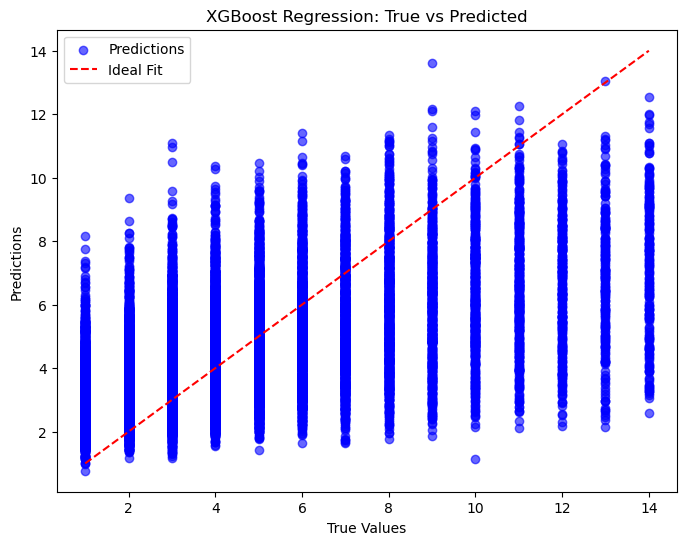

In [71]:
# # #  visualizing the output for XGBoost Regression 
import matplotlib.pyplot as plt
y_pred_xgboost= xgboost_model.predict(X_test)
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_xgboost, color='blue', alpha=0.6,label='Predictions')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--', label='Ideal Fit') 
plt.xlabel('True Values')
plt.ylabel('Predictions')
plt.title('XGBoost Regression: True vs Predicted')
plt.legend()
plt.show()


#### 3.1.7: Visualise the output for non-linear regression
Try to plot histogram of features, useful information can be found [here](https://matplotlib.org/stable/gallery/statistics/hist.html)

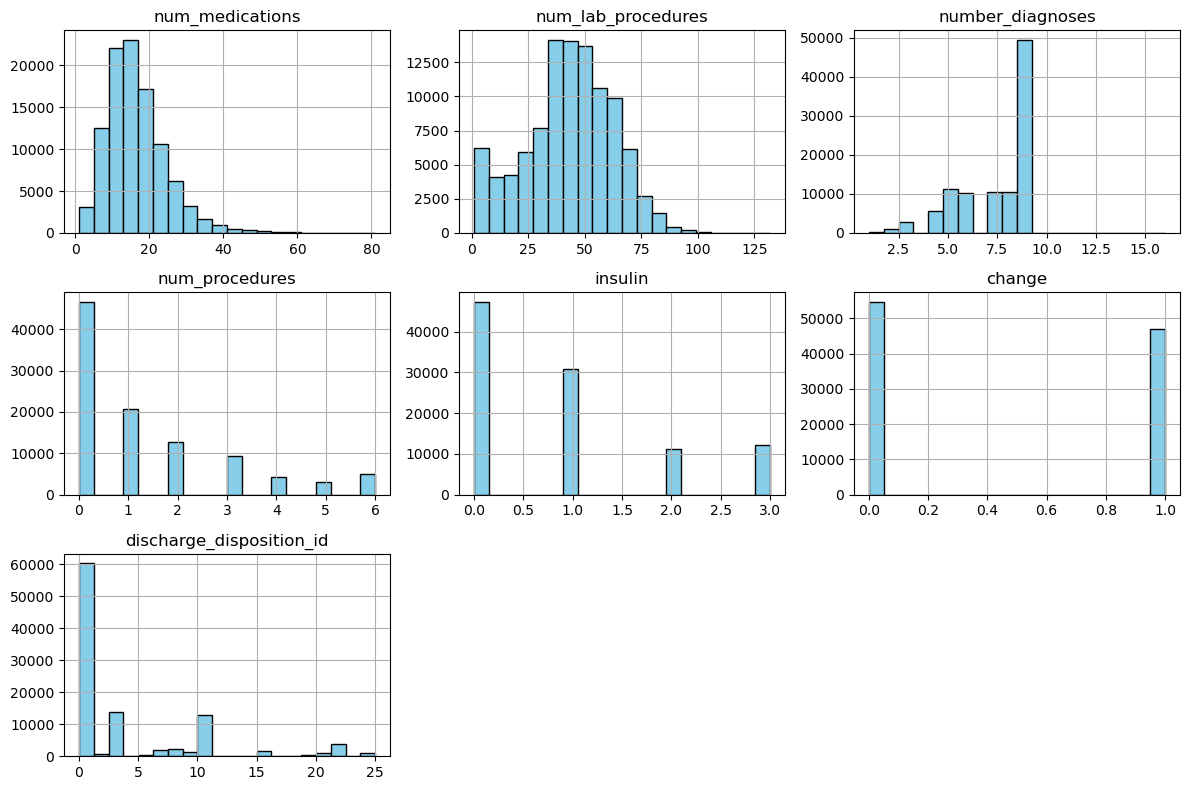

In [72]:
## Write visualisation code here
import matplotlib.pyplot as plt

# Select the features to visualize
v = data[['num_medications', 'num_lab_procedures', 'number_diagnoses', 'num_procedures', 'insulin','change','discharge_disposition_id']]
v.hist(bins=20, figsize=(12, 8), color='skyblue', edgecolor='black')
plt.tight_layout()
plt.show()



#### 3.1.8: Evaluation and Model Comparison
compare the performance of all four models: Linear Regression, Decision Tree Regression, Gradient Boosting, and XGBoost. Summarise each model’s performance using a comparison table.


In [73]:
import pandas as pd

# Sample comparison table
results = {
    "Model": ["Linear Regression", "Decision Tree", "Gradient Boosting", "XGBoost"],
    "MAE": [mae_linear,mae_dt,mae_gboost,mae_xgboost],
    "MSE": [mse_linear,mse_dt,mse_gboost,mse_xgboost],
    "RMSE": [rmse_linear,rmse_dt,rmse_gboost,rmse_xgboost],
}

results_df = pd.DataFrame(results)
print(results_df)

               Model       MAE       MSE      RMSE
0  Linear Regression  1.917395  6.322751  2.514508
1      Decision Tree  1.833769  5.914079  2.431888
2  Gradient Boosting  1.794063  5.646100  2.376152
3            XGBoost  1.793466  5.636957  2.374228


++++++++
### **3.2: Implementing Classification Baseline**


#### 3.2.1: Loading the data
- Use pandas to load the dataset.

In [74]:
import pandas as pd
# # # Loading the data
cdata=pd.read_csv('data/cleaned_data.csv')
cdata.head()

,gender,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,...,race_Other,age_[10-20),age_[20-30),age_[30-40),age_[40-50),age_[50-60),age_[60-70),age_[70-80),age_[80-90),age_[90-100)
0,0,2,24,9,1,41,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,1,1,2,3,59,0,18,0,0,...,0,1,0,0,0,0,0,0,0,0
2,0,1,1,2,2,11,5,13,2,0,...,0,0,1,0,0,0,0,0,0,0
3,1,1,1,2,2,44,1,16,0,0,...,0,0,0,1,0,0,0,0,0,0
4,1,1,1,2,1,51,0,8,0,0,...,0,0,0,0,1,0,0,0,0,0


In [75]:
# # #  Checking correlation between features and target

correlation_matrix = cdata.corr()
diabetesMed_corr = correlation_matrix['diabetesMed'].sort_values(ascending=False)
print(diabetesMed_corr)


diabetesMed                 1.000000
change                      0.506370
insulin                     0.473723
metformin                   0.251128
glipizide                   0.189360
num_medications             0.186910
glyburide                   0.170293
pioglitazone                0.145959
rosiglitazone               0.136066
glimepiride                 0.117763
repaglinide                 0.063524
time_in_hospital            0.062520
readmitted                  0.060493
glyburide-metformin         0.044738
nateglinide                 0.043817
num_lab_procedures          0.033107
acarbose                    0.029214
number_inpatient            0.026001
number_emergency            0.025923
number_diagnoses            0.021186
admission_type_id           0.019994
age_[10-20)                 0.019310
age_[60-70)                 0.016795
number_outpatient           0.016456
gender                      0.015901
chlorpropamide              0.015222
race_Other                  0.011281
t

#### 3.2.2:  Prepare Data for Classification


In [76]:
# # # importing required sklearn packages
from sklearn.model_selection import train_test_split


# # # Defining target and features
X = cdata[['time_in_hospital', 'num_lab_procedures','num_medications', 'number_outpatient',
       'number_emergency', 'number_inpatient',
       'number_diagnoses']]
y = cdata['diabetesMed']

# # # Splitting data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)



In [77]:
# # # Standardizing numerical columns
from sklearn.preprocessing import MinMaxScaler

# # #  List of numerical columns to scale
numerical_columns = [ 'time_in_hospital', 'num_lab_procedures',
        'num_medications', 'number_outpatient',
       'number_emergency', 'number_inpatient',
       'number_diagnoses']

# # #  Initializing scaler
scaler = MinMaxScaler()

X_train[numerical_columns] = scaler.fit_transform(X_train[numerical_columns])

X_test[numerical_columns] = scaler.transform(X_test[numerical_columns])

print(X_train[numerical_columns].head())

       time_in_hospital  num_lab_procedures  num_medications  \
24079          0.230769            0.358779           0.1250   
98079          0.000000            0.312977           0.0500   
6237           0.230769            0.328244           0.1125   
72208          0.153846            0.404580           0.0875   
33075          0.769231            0.259542           0.2750   

       number_outpatient  number_emergency  number_inpatient  number_diagnoses  
24079                0.0               0.0          0.000000          0.533333  
98079                0.0               0.0          0.000000          0.333333  
6237                 0.0               0.0          0.000000          0.400000  
72208                0.0               0.0          0.000000          0.466667  
33075                0.0               0.0          0.052632          0.466667  


In [78]:
X_train.head()

,time_in_hospital,num_lab_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
24079,0.230769,0.358779,0.1250,0.0,0.0,0.000000,0.533333
98079,0.000000,0.312977,0.0500,0.0,0.0,0.000000,0.333333
6237,0.230769,0.328244,0.1125,0.0,0.0,0.000000,0.400000
72208,0.153846,0.404580,0.0875,0.0,0.0,0.000000,0.466667
33075,0.769231,0.259542,0.2750,0.0,0.0,0.052632,0.466667


#### 3.2.3:  Implement Logistic Regression as a Baseline Model

In [79]:
# importing requires sklearn packages
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,precision_score,f1_score,recall_score
from sklearn.model_selection import cross_val_score

# Initialising and training Logistic Regression model
logistic_model = LogisticRegression(class_weight='balanced',random_state=42, max_iter=200)
# # # doing cross val 
cv_scores = cross_val_score(logistic_model, X, y, cv=5, scoring='accuracy')
# # # fitting the model 

logistic_model.fit(X_train, y_train)

# Predictions
y_pred_logistic = logistic_model.predict(X_test)

# Evaluation
accuracy_logistic = accuracy_score(y_test, y_pred_logistic)
precision_logistic=precision_score(y_test,y_pred_logistic)
f_1_score_logistic=f1_score(y_test,y_pred_logistic)
recall_logistic=recall_score(y_test,y_pred_logistic)

print(f"Logistic Regression Accuracy: {accuracy_logistic}")
print(f"Logistic Regression precision: {precision_logistic}")
print(f"Logistic Regression f1_score: {f_1_score_logistic}")
print(f"Logistic Regression recall_score: {recall_logistic}")
print(f"Cross-validation accuracy scores: {cv_scores}")

Logistic Regression Accuracy: 0.5594477743932397
Logistic Regression precision: 0.8351626619203006
Logistic Regression f1_score: 0.6532348505355969
Logistic Regression recall_score: 0.5363901943350692
Cross-validation accuracy scores: [0.52235433 0.5436545  0.55986832 0.59381909 0.59150985]


In [80]:
# # # Evaluating  Logistic Regression model on Training Set
y_train_pred_lo = logistic_model.predict(X_train)
accuracy_logistic_train = accuracy_score(y_train, y_train_pred_lo)
precision_logistic_train=precision_score(y_train,y_train_pred_lo)
f_1_score_logistic_train=f1_score(y_train,y_train_pred_lo)
recall_logistic_train=recall_score(y_train,y_train_pred_lo)

print(f"Logistic Regression Accuracy: {accuracy_logistic_train}")
print(f"Logistic Regression precision: {precision_logistic_train}")
print(f"Logistic Regression f1_score: {f_1_score_logistic_train}")
print(f"Logistic Regression recall_score: {recall_logistic_train}")

Logistic Regression Accuracy: 0.5650395519088095
Logistic Regression precision: 0.8395317492012779
Logistic Regression f1_score: 0.6551358089617358
Logistic Regression recall_score: 0.5371544468754491


#### 3.2.4: Implement Random Forest Classifier as a Non-linear Baseline

In [81]:
# importing requires sklearn packages
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import cross_val_score
# Initialising and train Random Forest Classifier
rf_model = RandomForestClassifier(random_state=42 ,class_weight='balanced',max_depth= 10, min_samples_leaf= 1, min_samples_split= 2,n_estimators= 300)
# # # doing cross val 
cv_scores = cross_val_score(rf_model, X, y, cv=5, scoring='accuracy')
# # # fitting the model 

rf_model.fit(X_train, y_train)

# Predictions
y_pred_rf = rf_model.predict(X_test)

# Evaluation
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)


print(f"Random Forest Accuracy: {accuracy_rf}")
print(f"Random Forest Precision: {precision_rf}")
print(f"Random Forest Recall: {recall_rf}")
print(f"Random Forest F1 Score: {f1_rf}")
print(f"Cross-validation accuracy scores: {cv_scores}")

Random Forest Accuracy: 0.6451803085388621
Random Forest Precision: 0.8269909467546417
Random Forest Recall: 0.6845548075701765
Random Forest F1 Score: 0.7490618485059068
Cross-validation accuracy scores: [0.60774295 0.62747507 0.6456542  0.67474082 0.67872058]


In [82]:
# # #  Evaluating Random Forest on Training Set
y_train_pred_rf = rf_model.predict(X_train)
accuracy_train_rf = accuracy_score(y_train, y_train_pred_rf)
precision_train_rf = precision_score(y_train, y_train_pred_rf)
recall_train_rf = recall_score(y_train, y_train_pred_rf)
f1_train_rf = f1_score(y_train, y_train_pred_rf)

print(f"Random Forest Training Accuracy: {accuracy_train_rf}")
print(f"Random Forest Training Precision: {precision_train_rf}")
print(f"Random Forest Training Recall: {recall_train_rf}")
print(f"Random Forest Training F1 Score: {f1_train_rf}")


Random Forest Training Accuracy: 0.6688080381270575
Random Forest Training Precision: 0.8448295872180742
Random Forest Training Recall: 0.6975102607917978
Random Forest Training F1 Score: 0.7641341906136553


#### 3.2.5: Implement K-Nearest Neighbors (KNN) Classifier

In [83]:
# # # importing requires sklearn packages
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import cross_val_score
# # # Initialising and training the KNN model
knn_model = KNeighborsClassifier(n_neighbors=15, weights='uniform') 
# # # doing cross val 
cv_scores = cross_val_score(knn_model, X, y, cv=5, scoring='accuracy')
# # # fitting the model

knn_model.fit(X_train, y_train)

# # # Predictions
y_pred_knn = knn_model.predict(X_test)

# # # Evaluation
accuracy_knn = accuracy_score(y_test, y_pred_knn)
precision_knn = precision_score(y_test, y_pred_knn)
recall_knn = recall_score(y_test, y_pred_knn)
f1_knn = f1_score(y_test, y_pred_knn)


print(f"KNN Accuracy: {accuracy_knn}")
print(f"KNN Precision: {precision_knn}")
print(f"KNN Recall: {recall_knn}")
print(f"KNN F1 Score: {f1_knn}")
print(f"Cross-validation accuracy scores: {cv_scores}")

KNN Accuracy: 0.7694802004519996
KNN Precision: 0.7850144389438944
KNN Recall: 0.9667852152927727
KNN F1 Score: 0.8664693494222778
Cross-validation accuracy scores: [0.76186499 0.76303248 0.76460473 0.76622611 0.76715963]


In [84]:
# # # Evaluating KNN on Training Set
y_train_pred_knn = knn_model.predict(X_train)
accuracy_train_knn = accuracy_score(y_train, y_train_pred_knn)
precision_train_knn = precision_score(y_train, y_train_pred_knn)
recall_train_knn = recall_score(y_train, y_train_pred_knn)
f1_train_knn = f1_score(y_train, y_train_pred_knn)

print(f"KNN Training Accuracy: {accuracy_train_knn}")
print(f"KNN Training Precision: {precision_train_knn}")
print(f"KNN Training Recall: {recall_train_knn}")
print(f"KNN Training F1 Score: {f1_train_knn}")


KNN Training Accuracy: 0.7799341620399941
KNN Training Precision: 0.7877512134203649
KNN Training Recall: 0.9771627513295111
KNN Training F1 Score: 0.8722931071352199


#### 3.2.6: Evaluation and Model Comparison
Compare the performance of implemented models using four metrics including "Accuracy", "Precision", "Recall", and "F1-score".

In [85]:
# # # Comparing the performance of implemented models 

results = {
    "Model": ["Logistic Regression", "Random Forest", "K-Nearest Neighbors"],
    "Accuracy": [accuracy_logistic,accuracy_rf,accuracy_knn],
    "Precision": [precision_logistic,precision_rf, precision_knn],
    "Recall": [recall_logistic, recall_rf, recall_knn],
    "F1 Score": [f_1_score_logistic, f1_rf, f1_knn] 
}

results_df = pd.DataFrame(results)
print(results_df)

                 Model  Accuracy  Precision    Recall  F1 Score
0  Logistic Regression  0.559448   0.835163  0.536390  0.653235
1        Random Forest  0.645180   0.826991  0.684555  0.749062
2  K-Nearest Neighbors  0.769480   0.785014  0.966785  0.866469


++++++++
### **Task 3.3: Implementing Clustering Baseline**


#### 3.3.1: Load and Preprocess the Data

In [6]:
import pandas as pd
from sklearn.preprocessing import StandardScaler,MinMaxScaler

# # # Load the dataset
clust_data=pd.read_csv('data/cleaned_data.csv')

# # # Standardising column names and remove duplicates
clust_data = clust_data.drop_duplicates()

# # # Applying standard scaling to numerical features for clustering
columns= ['time_in_hospital', 'num_lab_procedures',
       'num_procedures', 'num_medications', 'number_outpatient',
       'number_emergency', 'number_inpatient','num_procedures']
scaler = MinMaxScaler()
clust_data[columns] = scaler.fit_transform(clust_data[columns])

# Print the first few rows of the scaled data
print(clust_data[columns].head())

   time_in_hospital  num_lab_procedures  num_procedures  num_medications  \
0          0.000000            0.305344        0.000000           0.0000   
1          0.153846            0.442748        0.000000           0.2125   
2          0.076923            0.076336        0.833333           0.1500   
3          0.076923            0.328244        0.166667           0.1875   
4          0.000000            0.381679        0.000000           0.0875   

   number_outpatient  number_emergency  number_inpatient  num_procedures  
0           0.000000               0.0          0.000000        0.000000  
1           0.000000               0.0          0.000000        0.000000  
2           0.047619               0.0          0.047619        0.833333  
3           0.000000               0.0          0.000000        0.166667  
4           0.000000               0.0          0.000000        0.000000  


In [7]:
clust_data.columns

Index(['gender', 'admission_type_id', 'discharge_disposition_id',
       'admission_source_id', 'time_in_hospital', 'num_lab_procedures',
       'num_procedures', 'num_medications', 'number_outpatient',
       'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3',
       'number_diagnoses', 'metformin', 'repaglinide', 'nateglinide',
       'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide',
       'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose',
       'miglitol', 'troglitazone', 'tolazamide', 'insulin',
       'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted',
       'race_Asian', 'race_Caucasian', 'race_Hispanic', 'race_Other',
       'age_[10-20)', 'age_[20-30)', 'age_[30-40)', 'age_[40-50)',
       'age_[50-60)', 'age_[60-70)', 'age_[70-80)', 'age_[80-90)',
       'age_[90-100)'],
      dtype='object')

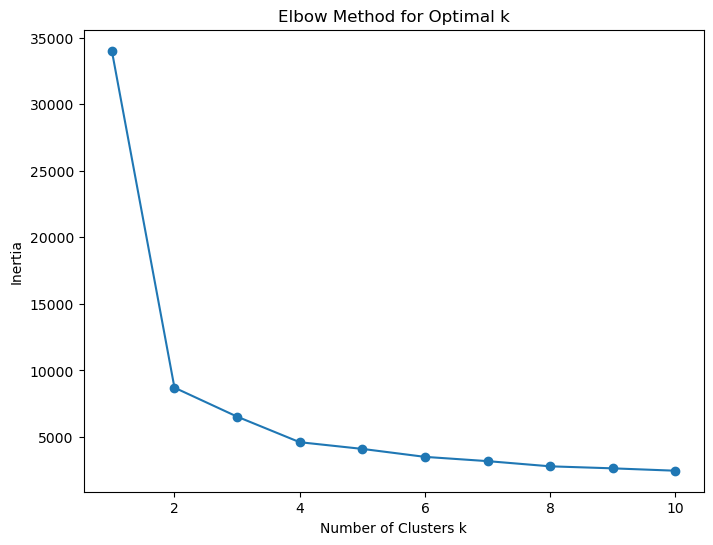

In [8]:
# # # doing the Elbow Method for Optimal K

import matplotlib.pyplot as plt
from sklearn.cluster import KMeans


# # # features
X_train = clust_data[['num_medications', 'num_lab_procedures','gender', 
                'time_in_hospital']]


k_range = range(1, 11)
inertia = []

# # # Fitting KMeans for different values of k
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_train)
    inertia.append(kmeans.inertia_)

# # # Plotting the Elbow curve
plt.figure(figsize=(8, 6))
plt.plot(k_range, inertia, marker='o')
plt.title('Elbow Method for Optimal k')
plt.xlabel('Number of Clusters k')
plt.ylabel('Inertia')
plt.show()


In [89]:
X_train

,num_medications,num_lab_procedures,gender,admission_type_id,time_in_hospital
0,0.0000,0.305344,0,2,0.000000
1,0.2125,0.442748,0,1,0.153846
2,0.1500,0.076336,0,1,0.076923
3,0.1875,0.328244,1,1,0.076923
4,0.0875,0.381679,1,1,0.000000
...,...,...,...,...,...
101761,0.1875,0.381679,1,1,0.153846
101762,0.2125,0.244275,0,1,0.307692
101763,0.1000,0.396947,1,1,0.000000
101764,0.2500,0.335878,0,7,0.692308


#### 3.3.2: Implement K-Means Clustering

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


# # # Initialize and train the K-Means model
kmeans = KMeans(n_clusters=2, random_state=42)  
kmeans.fit(X_train)  

# # # Predict clusters and evaluate
cluster_labels = kmeans.labels_
kmean_silhouette= silhouette_score(X_train, cluster_labels)  

# # # Printing the Silhouette Score
print(f"K-Means Silhouette Score: {kmean_silhouette}")


#### 3.3.3: Apply PCA for Dimensionality Reduction

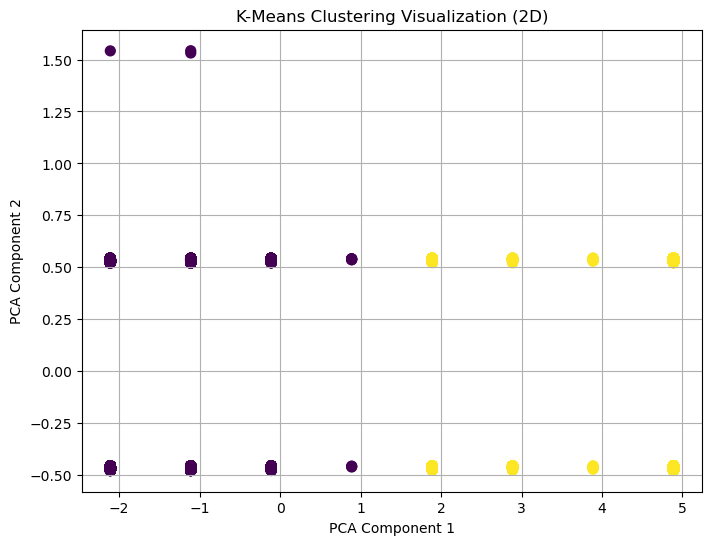

In [91]:
# # # Applying PCA to reduce dimensions to 2 for 2D visualization

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2) 
X_pca = pca.fit_transform(X_train)

# Visualizing clusters in 2D
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=cluster_labels, cmap='viridis', s=50)  
plt.title('K-Means Clustering Visualization (2D)')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.grid(True)
plt.show()


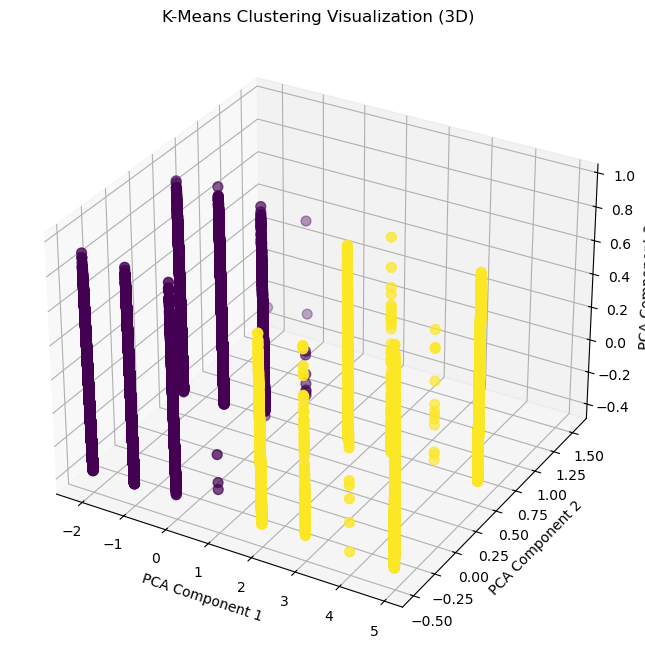

In [92]:
# # # Applying visualization  for kmeans 

from mpl_toolkits.mplot3d import Axes3D

pca = PCA(n_components=3)
X_pca_3d = pca.fit_transform(X_train)

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
scatter = ax.scatter(X_pca_3d[:, 0], X_pca_3d[:, 1], X_pca_3d[:, 2], 
                      c=cluster_labels, cmap='viridis', s=50)
ax.set_title('K-Means Clustering Visualization (3D)')
ax.set_xlabel('PCA Component 1')
ax.set_ylabel('PCA Component 2')
ax.set_zlabel('PCA Component 3')
plt.show()


#### 3.3.4: Implement Random Hierarchical Clustering

In [93]:
# # # Implementing RHC

from sklearn.utils import resample
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# #  # sampleing 10000 rows from the dataset
X_sampled = resample(X_train, n_samples=10000, random_state=42)

# # # Initializing  and fitting  hierarchical clustering
hierarchical = AgglomerativeClustering(n_clusters=2)
cluster_labels = hierarchical.fit_predict(X_sampled)

# # # Evaluate the clustering with Silhouette Score
hierarchical_silhouette = silhouette_score(X_sampled, cluster_labels)
print(f"Hierarchical Clustering Silhouette Score: {hierarchical_silhouette}")

Hierarchical Clustering Silhouette Score: 0.7841004378075328


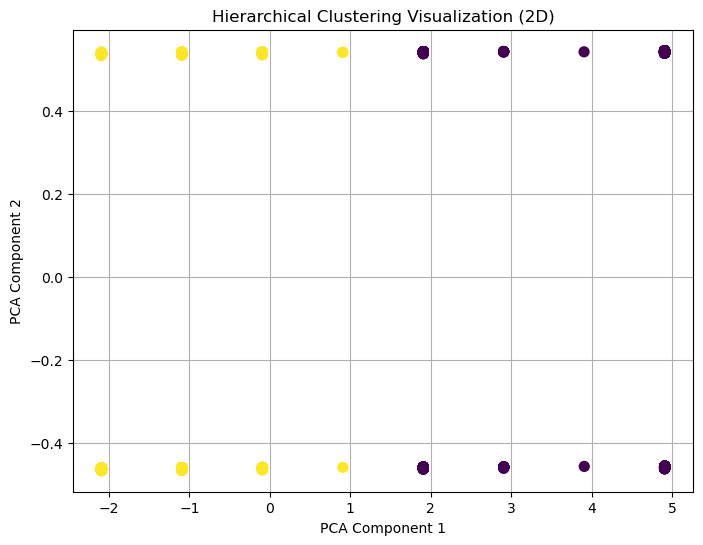

In [94]:
# # # Applying visualization for Random Hierarchical Clustering
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Apply PCA to reduce dimensions
pca = PCA(n_components=2) 
X_pca = pca.fit_transform(X_sampled)

# Visualize hierarchical clustering in 2D
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=cluster_labels, cmap='viridis', s=50)  
plt.title('Hierarchical Clustering Visualization (2D)')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.grid(True)
plt.show()


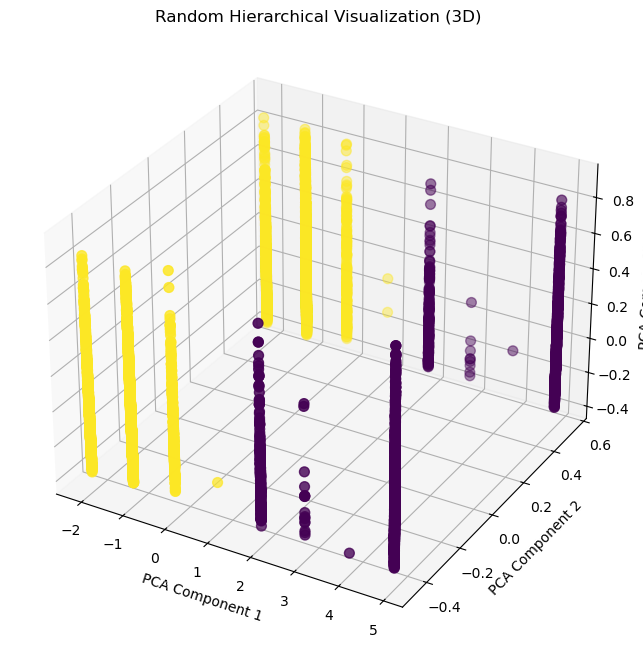

In [95]:
# # # Applying visualization for Random Hierarchical Clustering
from mpl_toolkits.mplot3d import Axes3D

pca = PCA(n_components=3)
X_pca_3d = pca.fit_transform(X_sampled)

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
scatter = ax.scatter(X_pca_3d[:, 0], X_pca_3d[:, 1], X_pca_3d[:, 2], 
                      c=cluster_labels, cmap='viridis', s=50)
ax.set_title('Random Hierarchical Visualization (3D)')
ax.set_xlabel('PCA Component 1')
ax.set_ylabel('PCA Component 2')
ax.set_zlabel('PCA Component 3')
plt.show()

#### 3.3.5: Implement DBSCAN for Density-Based Clustering

In [96]:
X_train

,num_medications,num_lab_procedures,gender,admission_type_id,time_in_hospital
0,0.0000,0.305344,0,2,0.000000
1,0.2125,0.442748,0,1,0.153846
2,0.1500,0.076336,0,1,0.076923
3,0.1875,0.328244,1,1,0.076923
4,0.0875,0.381679,1,1,0.000000
...,...,...,...,...,...
101761,0.1875,0.381679,1,1,0.153846
101762,0.2125,0.244275,0,1,0.307692
101763,0.1000,0.396947,1,1,0.000000
101764,0.2500,0.335878,0,7,0.692308


In [97]:

from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

#  # # Initialising and fiting DBSCAN
dbscan = DBSCAN(eps=0.9, min_samples=3)  
dbscan_labels = dbscan.fit_predict(X_train)

# # # Filtering noise points (labeled as -1)
filtered_data = X_train[dbscan_labels != -1]
filtered_labels = dbscan_labels[dbscan_labels != -1]

# # #  Evaluate with Silhouette Score (excluding noise)

dbscan_silhouette = silhouette_score(filtered_data, filtered_labels)
print(f"DBSCAN Silhouette Score (excluding noise): {dbscan_silhouette}")


DBSCAN Silhouette Score (excluding noise): 0.6735095965545232


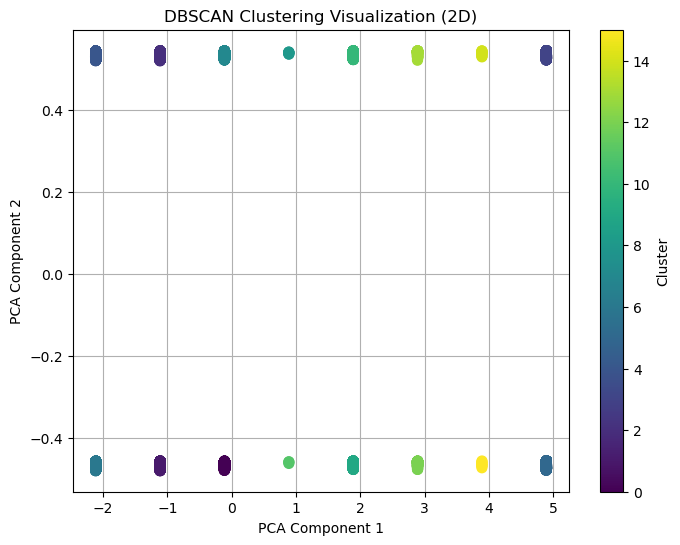

In [98]:
# # # Applying visualization for DBSCAN
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# PCA for 2D visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(filtered_data)

plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=filtered_labels, cmap='viridis', s=50)
plt.title('DBSCAN Clustering Visualization (2D)')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.colorbar(label='Cluster')
plt.grid(True)
plt.show()


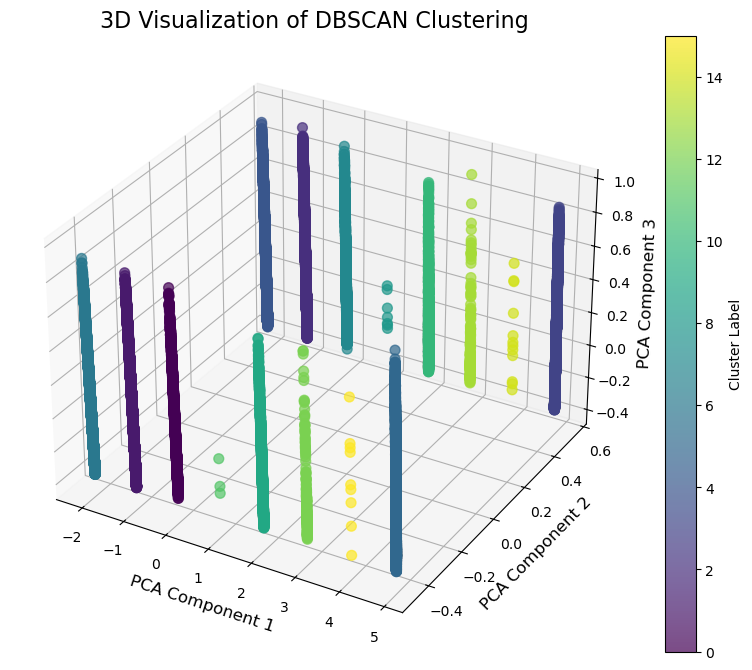

In [99]:
# # # Applying visualization for DBSCAN
pca = PCA(n_components=3)
X_pca_3d = pca.fit_transform(filtered_data)

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(X_pca_3d[:, 0], X_pca_3d[:, 1], X_pca_3d[:, 2],
                      c=filtered_labels, cmap='viridis', s=50, alpha=0.7)
ax.set_title('3D Visualization of DBSCAN Clustering ', fontsize=16)
ax.set_xlabel('PCA Component 1', fontsize=12)
ax.set_ylabel('PCA Component 2', fontsize=12)
ax.set_zlabel('PCA Component 3', fontsize=12)
plt.colorbar(scatter, ax=ax, label='Cluster Label')

plt.show()

#### 3.3.6: Evaluation and Model Comparison

In [100]:
# # # Summary of Silhouette Scores
import pandas as pd

results = {
    "Clustering Method": ["K-Means", "Hierarchical", "DBSCAN"],
    "Silhouette Score": [kmean_silhouette, hierarchical_silhouette, dbscan_silhouette]
}

results_df = pd.DataFrame(results)
print(results_df)


  Clustering Method  Silhouette Score
0           K-Means          0.787573
1      Hierarchical          0.784100
2            DBSCAN          0.673510


++++++++++
### **3.4 Feature Engineering and Feature Selection**
Select the most relevant features to improve model performance

In [101]:
# # # loding the data and naming it fdata
import pandas as pd
fdata=pd.read_csv('data/cleaned_data.csv')
fdata.head()

,gender,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,...,race_Other,age_[10-20),age_[20-30),age_[30-40),age_[40-50),age_[50-60),age_[60-70),age_[70-80),age_[80-90),age_[90-100)
0,0,2,24,9,1,41,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,1,1,2,3,59,0,18,0,0,...,0,1,0,0,0,0,0,0,0,0
2,0,1,1,2,2,11,5,13,2,0,...,0,0,1,0,0,0,0,0,0,0
3,1,1,1,2,2,44,1,16,0,0,...,0,0,0,1,0,0,0,0,0,0
4,1,1,1,2,1,51,0,8,0,0,...,0,0,0,0,1,0,0,0,0,0


#### 3.4.1: Feature Engineering

In [102]:
# # # # Ratio between admission type and discharge disposition
fdata['admission_discharge_ratio'] = (fdata['admission_type_id'] / (fdata['discharge_disposition_id'] + 1))  
# # # # Ratio between admission source and type
fdata['admission_source_ratio'] = (fdata['admission_source_id'] / (fdata['admission_type_id'] + 1))
# # # # gender and number of medication
fdata['gender_lab_procedures'] = fdata['gender'] * fdata['num_lab_procedures']
# # # age and medication
fdata['age_medications'] = fdata['age_[60-70)'] * fdata['num_medications']

In [103]:
# Interaction feature example

# # # Lab Procedures Per Day
fdata['lab_procedures_per_day'] = fdata['num_lab_procedures'] / (fdata['time_in_hospital'] + 1)

# # # Medications Per Diagnosis
fdata['medications_per_diagnosis'] = fdata['num_medications'] / (fdata['number_diagnoses'] + 1)
# # # Procedures and Emergency Visits
fdata['procedures_and_emergency'] = fdata['num_procedures'] * fdata['number_emergency']
# # # Interaction between 'num_medications' and 'number_emergency'
fdata['medication_emergency_interaction'] = fdata['num_medications'] * fdata['number_emergency']

#  # # Interaction between 'num_medications' and 'num_lab_procedures'
fdata['medication_lab_interaction'] = fdata['num_medications'] * fdata['num_lab_procedures']

# # #  Interaction between 'time_in_hospital' and 'num_procedures'
fdata['time_in_hospital_procedures_interaction'] = fdata['time_in_hospital'] * fdata['num_procedures']

# # # Interaction between 'num_lab_procedures' and 'num_procedures' 
fdata['lab_procedure_procedures_interaction'] = fdata['num_lab_procedures'] * fdata['num_procedures']


In [104]:
# # #  Total visits
fdata['total_visits'] = fdata['number_outpatient'] + fdata['number_emergency'] + fdata['number_inpatient']
# # # medication per visit
fdata['medication_per_visit'] = fdata['num_medications'] / (fdata['total_visits'] + 1)

# # # Creating  the binary feature for change_and_med
fdata['change_and_med'] = ((fdata['change'] == 1) & (fdata['diabetesMed'] == 1)).astype(int)

#### 3.4.2: Generate Statistical Features
Calculate aggregate statistics such as mean, max, min, or standard deviation for features if relevant

In [105]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# #  # Generating  statistical features for the numerical columns

columns = ['medication_per_visit','total_visits','lab_procedure_procedures_interaction','time_in_hospital_procedures_interaction',
          'medication_lab_interaction','medication_emergency_interaction','procedures_and_emergency','medications_per_diagnosis','lab_procedures_per_day',
           'age_medications','gender_lab_procedures'
]

agg_columns = fdata[columns].describe()
print(agg_columns)


       medication_per_visit   total_visits  \
count         101766.000000  101766.000000   
mean              11.158994       1.202759   
std                8.285357       2.291781   
min                0.058824       0.000000   
25%                5.000000       0.000000   
50%                9.000000       0.000000   
75%               15.000000       2.000000   
max               81.000000      80.000000   

       lab_procedure_procedures_interaction  \
count                         101766.000000   
mean                              59.685239   
std                               90.758852   
min                                0.000000   
25%                                0.000000   
50%                               16.000000   
75%                               84.000000   
max                              726.000000   

       time_in_hospital_procedures_interaction  medication_lab_interaction  \
count                            101766.000000               101766.000000   
mean 

#### 3.4.3: Feature Transformation
Normalise or standardise features, especially for distance-based models like KNN or clustering

In [106]:
# # # Standardizing  numerical columns
from sklearn.preprocessing import StandardScaler,MinMaxScaler
numerical_columns = ['medication_per_visit','total_visits','lab_procedure_procedures_interaction','time_in_hospital_procedures_interaction',
          'medication_lab_interaction','medication_emergency_interaction','procedures_and_emergency','medications_per_diagnosis','lab_procedures_per_day',
           'age_medications','gender_lab_procedures'
]

# Initialize scaler
scaler = MinMaxScaler()

fdata[numerical_columns] = scaler.fit_transform(fdata[numerical_columns])
print(fdata[numerical_columns].head())

   medication_per_visit  total_visits  lab_procedure_procedures_interaction  \
0              0.011628        0.0000                              0.000000   
1              0.221657        0.0000                              0.000000   
2              0.039426        0.0375                              0.075758   
3              0.196948        0.0000                              0.060606   
4              0.098110        0.0000                              0.000000   

   time_in_hospital_procedures_interaction  medication_lab_interaction  \
0                                 0.000000                    0.006185   
1                                 0.000000                    0.164064   
2                                 0.119048                    0.021958   
3                                 0.023810                    0.108706   
4                                 0.000000                    0.062935   

   medication_emergency_interaction  procedures_and_emergency  \
0              

In [107]:
# # # checking the data 
print(fdata.head())
print(fdata.info())


   gender  admission_type_id  discharge_disposition_id  admission_source_id  \
0       0                  2                        24                    9   
1       0                  1                         1                    2   
2       0                  1                         1                    2   
3       1                  1                         1                    2   
4       1                  1                         1                    2   

   time_in_hospital  num_lab_procedures  num_procedures  num_medications  \
0                 1                  41               0                1   
1                 3                  59               0               18   
2                 2                  11               5               13   
3                 2                  44               1               16   
4                 1                  51               0                8   

   number_outpatient  number_emergency  ...  lab_procedures_per_day 

#### 3.4.4: Feature Selection
Use feature importance from tree-based models (Random Forest, Gradient Boosting) to select important features


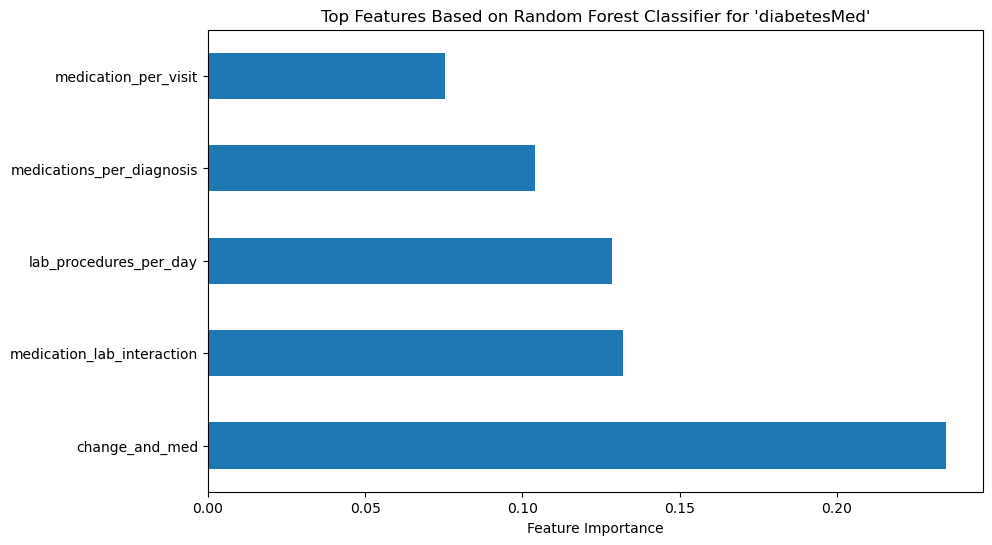

In [108]:
# # # feature importance for classification
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt
import pandas as pd
X_1_c = fdata[['medication_per_visit','total_visits','lab_procedure_procedures_interaction','time_in_hospital_procedures_interaction',
          'medication_lab_interaction','medication_emergency_interaction','procedures_and_emergency','medications_per_diagnosis','lab_procedures_per_day',
           'age_medications','gender_lab_procedures','admission_source_ratio','admission_discharge_ratio','change_and_med']]
y_1_c = fdata['diabetesMed'] 
# # #  Fit Random Forest model
model = RandomForestClassifier(random_state=42)
model.fit(X_1_c, y_1_c)

#  # # Get feature importance 
importances = pd.Series(model.feature_importances_, index=X_1_c.columns).sort_values(ascending=False)
top_importances = importances.head()
plt.figure(figsize=(10, 6))
top_importances.plot(kind='barh')
plt.xlabel("Feature Importance")
plt.title(f"Top Features Based on Random Forest Classifier for 'diabetesMed'")
plt.show()


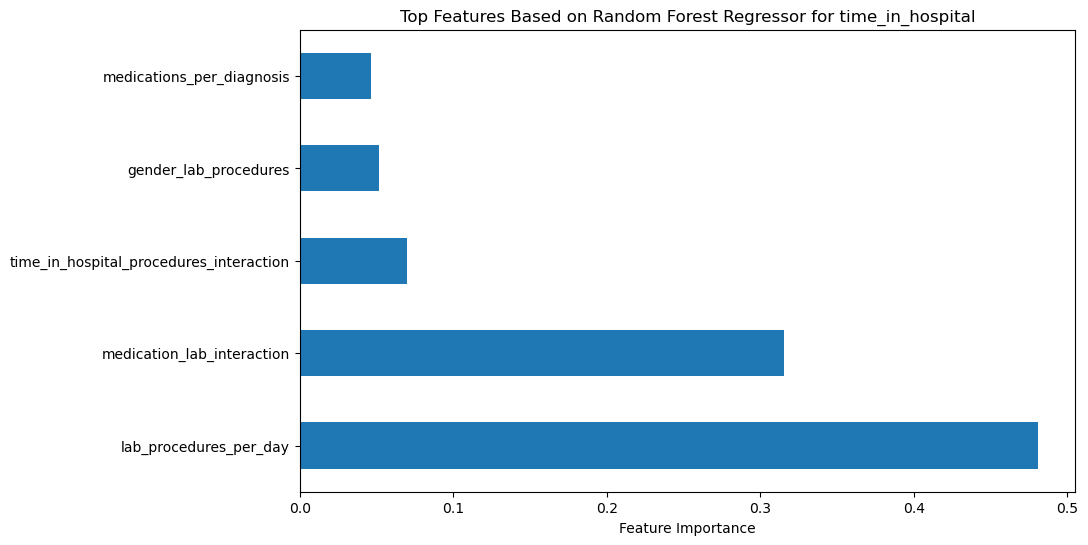

In [109]:
# # # feature importance for regression
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt
import pandas as pd
X_1 = fdata[['medication_per_visit','total_visits','lab_procedure_procedures_interaction','time_in_hospital_procedures_interaction',
          'medication_lab_interaction','medication_emergency_interaction','procedures_and_emergency','medications_per_diagnosis','lab_procedures_per_day',
           'age_medications','gender_lab_procedures','admission_source_ratio','admission_discharge_ratio','change_and_med']]
y_1 = fdata['time_in_hospital'] 
# # #  Fit Random Forest model
model = RandomForestRegressor(random_state=42)
model.fit(X_1, y_1)
#  # # Get feature importance 
importances = pd.Series(model.feature_importances_, index=X_1.columns).sort_values(ascending=False)
top_importances = importances.head()
plt.figure(figsize=(10, 6))
top_importances.plot(kind='barh')
plt.xlabel("Feature Importance")
plt.title(f"Top Features Based on Random Forest Regressor for time_in_hospital")
plt.show()

#### 3.4.5: Model Evaluation After Feature Selection
- After feature engineering and selection, evaluate your model with the new set of features.
- Apply cross-validation to measure the model’s performance with the refined feature set

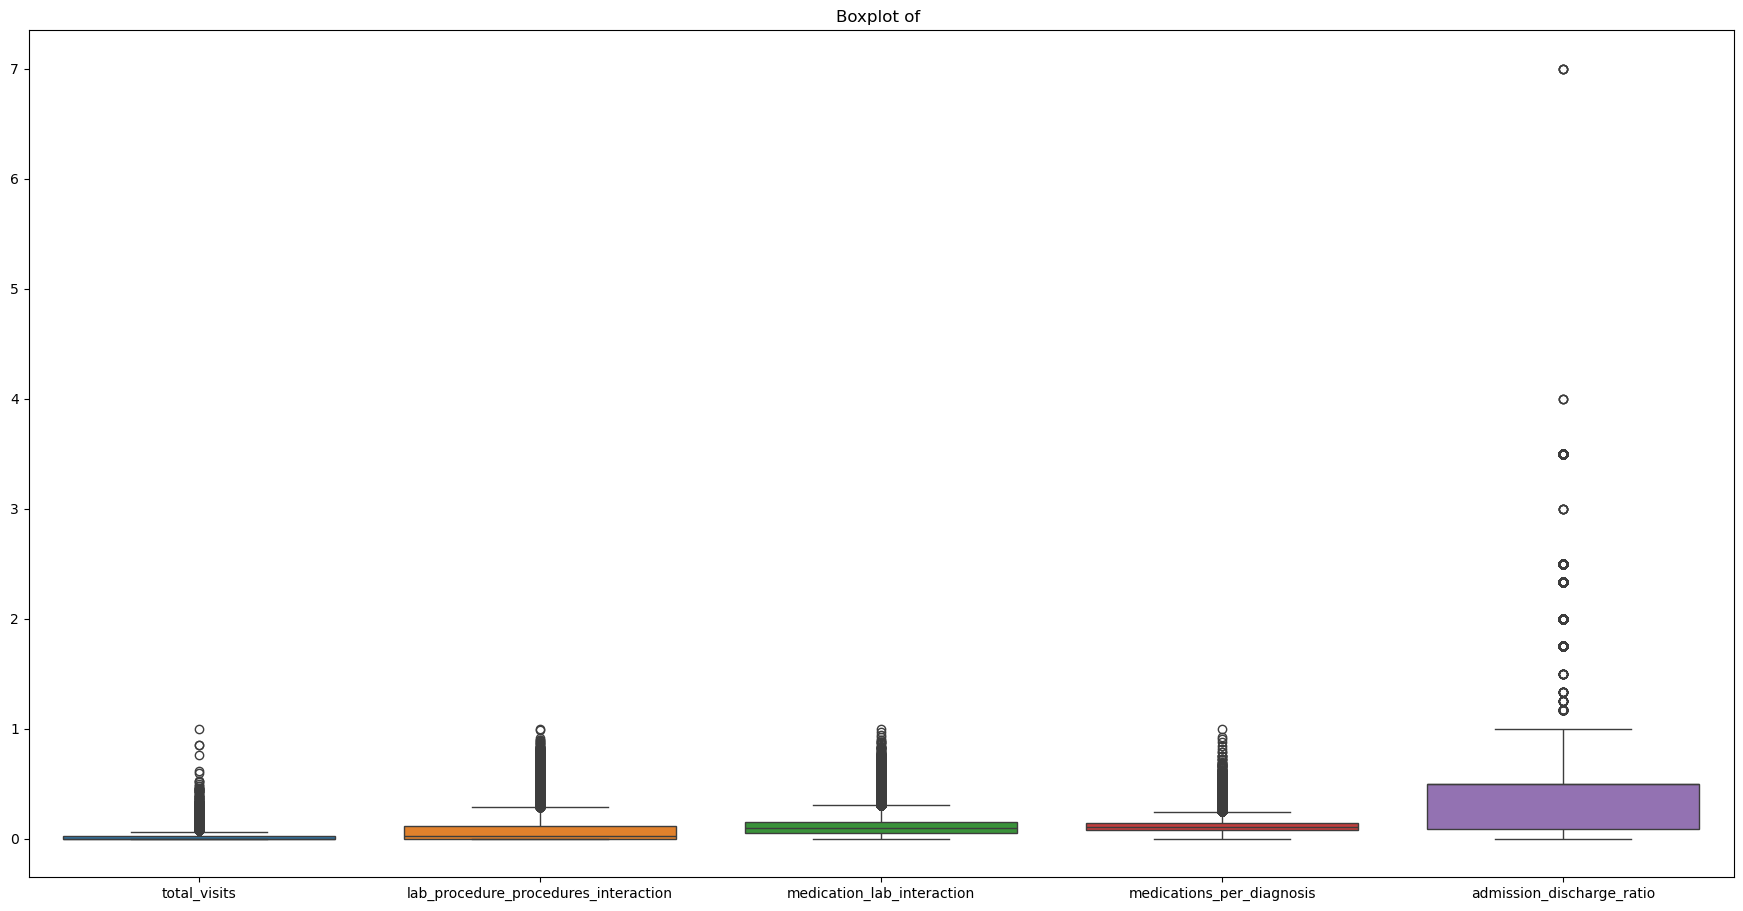

In [110]:
import matplotlib.pyplot as plt
import seaborn as sns
X = fdata[['total_visits', 'lab_procedure_procedures_interaction',
       'medication_lab_interaction', 'medications_per_diagnosis',
       'admission_discharge_ratio']]
plt.figure(figsize=(22, 11))
sns.boxplot(data=X)
plt.title(f'Boxplot of ')
plt.show()


In [111]:
### Using Cap for outliers

import pandas as pd

def cap_outliers(fdata, features):
    for feature in features:
        Q1 = fdata[feature].quantile(0.25)
        Q3 = fdata[feature].quantile(0.75)
        IQR = Q3 - Q1
        
        # Calculate bounds
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        
        # Convert bounds to the same dtype as the column in data
        if pd.api.types.is_integer_dtype(fdata[feature].dtype):
            lower_bound = int(lower_bound)
            upper_bound = int(upper_bound)
        elif pd.api.types.is_float_dtype(fdata[feature].dtype):
            lower_bound = float(lower_bound)
            upper_bound = float(upper_bound)

        # Cap the outliers
        fdata.loc[fdata[feature] < lower_bound, feature] = lower_bound
        fdata.loc[fdata[feature] > upper_bound, feature] = upper_bound

# List of features to cap based on the boxplot
features_to_cap = ['total_visits', 'lab_procedure_procedures_interaction', 'medication_lab_interaction',
                   'medications_per_diagnosis', 'admission_discharge_ratio']

# Cap outliers in the data
cap_outliers(fdata, features_to_cap)


In [112]:
# # # training LogisticRegression with new set of features and hyperparameter tuning

# # #  importing requires sklearn packages
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,precision_score,f1_score,recall_score
from sklearn.model_selection import cross_val_score,train_test_split

X = fdata[['total_visits', 'lab_procedure_procedures_interaction',
       'medication_lab_interaction', 'medications_per_diagnosis',
       'admission_discharge_ratio']]
y = fdata['diabetesMed']
# # # speliting the data to training and testing 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)
# # # Initialising and training Logistic Regression model
logistic_model_2 = LogisticRegression(C=0.001, max_iter= 100, penalty = 'l2', solver= 'liblinear',class_weight='balanced',random_state=42)

# # # doing cros vall
cv_scores = cross_val_score(logistic_model_2, X, y, cv=5, scoring='accuracy')
# # # fitting the model 
logistic_model_2.fit(X_train, y_train)


# # # Predictions
y_pred_logistic = logistic_model_2.predict(X_test)

# # # Evaluation
accuracy_logistic_2 = accuracy_score(y_test, y_pred_logistic)
precision_logistic_2=precision_score(y_test,y_pred_logistic)
f_1_score_logistic_2=f1_score(y_test,y_pred_logistic)
recall_logistic_2=recall_score(y_test,y_pred_logistic)


print(f"Logistic Regression Accuracy after feature selection: {accuracy_logistic_2}")
print(f"Logistic Regression precision after feature selection: {precision_logistic_2}")
print(f"Logistic Regression f1_score after feature selection: {f_1_score_logistic_2}")
print(f"Logistic Regression recall_score after feature selection: {recall_logistic_2}")
print(f"Cross-validated accuracy after feature selection:{cv_scores}")

Logistic Regression Accuracy after feature selection: 0.5855851429694409
Logistic Regression precision after feature selection: 0.824748743718593
Logistic Regression f1_score after feature selection: 0.6854607152179587
Logistic Regression recall_score after feature selection: 0.586422510049129
Cross-validated accuracy after feature selection:[0.5895647  0.61774677 0.57534516 0.56738564 0.53495799]


In [113]:
X_train

,total_visits,lab_procedure_procedures_interaction,medication_lab_interaction,medications_per_diagnosis,admission_discharge_ratio
53010,0.0125,0.000000,0.079790,0.132075,0.500000
73656,0.0375,0.000000,0.201175,0.140461,0.500000
73899,0.0000,0.101928,0.251585,0.132075,0.058824
83295,0.0000,0.000000,0.022112,0.044025,1.125000
100384,0.0000,0.000000,0.126024,0.094340,1.125000
...,...,...,...,...,...
9327,0.0375,0.000000,0.074068,0.209344,1.000000
73028,0.0000,0.066116,0.148291,0.119497,0.500000
98564,0.0250,0.000000,0.120767,0.100629,0.000000
78235,0.0625,0.086777,0.136230,0.081761,0.083333


In [114]:
# # # training  RandomForestClassifie with new set of features and hyperparameter tuning

# # # importing requires sklearn packages
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import cross_val_score

# # #  Initialising and train Random Forest Classifier
rf_model_2 = RandomForestClassifier(class_weight= None, max_depth= 10, max_features='sqrt', min_samples_leaf= 4, min_samples_split= 9, n_estimators= 561)
# # # doing cross val 
cv_scores = cross_val_score(rf_model_2, X, y, cv=5, scoring='accuracy')
# # # fitting the model 
rf_model_2.fit(X_train, y_train)

# # # Predictions
y_pred_rf = rf_model_2.predict(X_test)

# # # Evaluation
accuracy_rf_2 = accuracy_score(y_test, y_pred_rf)
precision_rf_2 = precision_score(y_test, y_pred_rf)
recall_rf_2 = recall_score(y_test, y_pred_rf)
f1_rf_2 = f1_score(y_test, y_pred_rf)

print(f"Random Forest Accuracy: {accuracy_rf_2}")
print(f"Random Forest Precision: {precision_rf_2}")
print(f"Random Forest Recall: {recall_rf_2}")
print(f"Random Forest F1 Score: {f1_rf_2}")
print("Cross-validated accuracy after feature selection:", cv_scores.mean())

Random Forest Accuracy: 0.777144541613442
Random Forest Precision: 0.7813084112149533
Random Forest Recall: 0.9867925732150833
Random Forest F1 Score: 0.8721100710499605
Cross-validated accuracy after feature selection: 0.7757797310408309


In [115]:
# # # training KNeighborsClassifier  with new set of features and hyperparameter tuning


# # #  importing requires sklearn packages
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import cross_val_score
# # #  Initialising and training the KNN model
knn_model_2 = KNeighborsClassifier(n_neighbors=21,metric='manhattan', weights='uniform') 
# # # doing cross val 
cv_scores = cross_val_score(knn_model_2, X, y, cv=5, scoring='accuracy')
knn_model_2.fit(X_train, y_train)

#  # # Predictions
y_pred_knn = knn_model_2.predict(X_test)

# # #  Evaluation
accuracy_knn_2 = accuracy_score(y_test, y_pred_knn)
precision_knn_2 = precision_score(y_test, y_pred_knn)
recall_knn_2 = recall_score(y_test, y_pred_knn)
f1_knn_2 = f1_score(y_test, y_pred_knn)

print(f"KNN Accuracy: {accuracy_knn_2}")
print(f"KNN Precision: {precision_knn_2}")
print(f"KNN Recall: {recall_knn_2}")
print(f"KNN F1 Score: {f1_knn_2}")
print("Cross-validated accuracy after feature selection:", cv_scores.mean())

KNN Accuracy: 0.7707084602535128
KNN Precision: 0.7835136527563111
KNN Recall: 0.9703311427295349
KNN F1 Score: 0.8669726078157513
Cross-validated accuracy after feature selection: 0.768812816952644


In [116]:
# # # Sample comparison table after new featurs selection and hyperparameter tuning:

results = {
    "Model": ["Logistic Regression", "Random Forest", "K-Nearest Neighbors"],
    "Accuracy": [accuracy_logistic_2,accuracy_rf_2,accuracy_knn_2],
    "Precision": [precision_logistic_2,precision_rf_2, precision_knn_2],
    "Recall": [recall_logistic_2, recall_rf_2, recall_knn_2],
    "F1 Score": [f_1_score_logistic_2, f1_rf_2, f1_knn_2]
}

results_df = pd.DataFrame(results)
print(results_df)

                 Model  Accuracy  Precision    Recall  F1 Score
0  Logistic Regression  0.585585   0.824749  0.586423  0.685461
1        Random Forest  0.777145   0.781308  0.986793  0.872110
2  K-Nearest Neighbors  0.770708   0.783514  0.970331  0.866973


# # # Retraining the Linear Regression, Decision Tree, Gradient Boosting, and XGBoost models after Feature Engineering and Feature Selection


In [117]:
# # # training  LinearRegression
from sklearn.metrics import mean_squared_error , mean_absolute_error
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split,cross_val_score,KFold
import pandas as pd
# Features and target
X = fdata[['medication_lab_interaction','medication_per_visit','medications_per_diagnosis','lab_procedure_procedures_interaction',
             'gender_lab_procedures','admission_discharge_ratio','admission_source_ratio','change_and_med','total_visits']]
y= fdata['time_in_hospital']
# Split dataset
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

# # # Initialising and training Linear Regression model
linear_model_2 = LinearRegression()

# # # doing cross val
kf = KFold(n_splits=6, shuffle=True, random_state=42)
cv_scores_mae = -cross_val_score(linear_model_2, X, y, cv=kf, scoring='neg_mean_absolute_error')
# # # fitting the model 

linear_model_2.fit(X_train, y_train)
# # # Predictions

y_pred_linear = linear_model_2.predict(X_test)

# # # Evaluation

mae_linear_2 = mean_absolute_error(y_test, y_pred_linear)
mse_linear_2 = mean_squared_error(y_test, y_pred_linear)
rmse_linear_2 = np.sqrt(mse_linear_2)

print(f'Linear Regression RMSE:{rmse_linear_2}')
print(f"Linear Regression MAE: {mae_linear_2}")
print(f"Linear Regression MSE: {mse_linear_2}")
print(f"Cross-Validation MAE Scores: {cv_scores_mae}")

Linear Regression RMSE:2.527420990551951
Linear Regression MAE: 1.927358283729393
Linear Regression MSE: 6.387856863482606
Cross-Validation MAE Scores: [1.92641483 1.96684191 1.93259028 1.94392301 1.94614363 1.94952729]


In [118]:
X_test

,medication_lab_interaction,medication_per_visit,medications_per_diagnosis,lab_procedure_procedures_interaction,gender_lab_procedures,admission_discharge_ratio,admission_source_ratio,change_and_med,total_visits
35956,0.210144,0.246366,0.203354,0.000000,0.000000,0.500000,7.000,0,0.0000
60927,0.021494,0.085756,0.042628,0.000000,0.151515,0.500000,4.500,0,0.0000
79920,0.074532,0.070312,0.174528,0.086777,0.000000,0.000000,9.000,0,0.0375
50078,0.082109,0.116642,0.143082,0.000000,0.212121,1.125000,1.125,0,0.0125
44080,0.019329,0.073401,0.040881,0.000000,0.000000,0.111111,1.000,0,0.0000
...,...,...,...,...,...,...,...,...,...
16156,0.133911,0.209302,0.112509,0.070248,0.386364,0.500000,1.000,0,0.0000
67386,0.121076,0.065165,0.094340,0.067493,0.371212,0.000000,9.000,1,0.0250
81342,0.107623,0.051781,0.100629,0.112948,0.000000,0.500000,1.000,0,0.0375
72915,0.016855,0.061047,0.033019,0.000000,0.166667,1.125000,0.250,0,0.0000


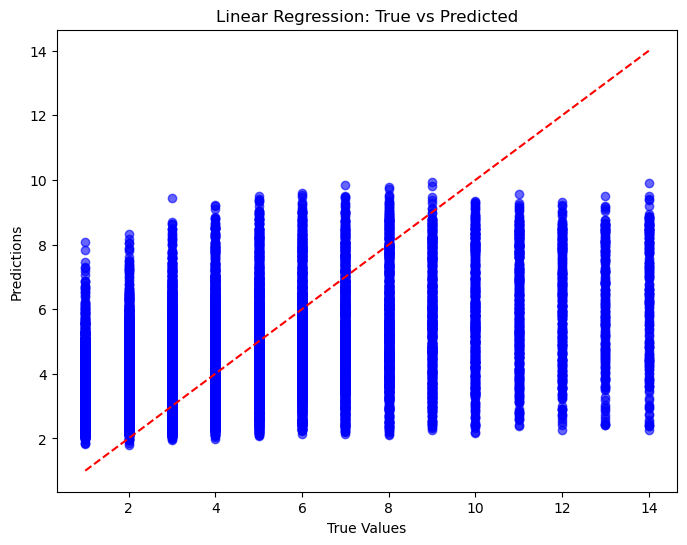

In [119]:
# # #  visualizing the output for Linear Regression
import matplotlib.pyplot as plt
y_pred_linear= linear_model_2.predict(X_test)
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_linear, color='blue', alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--') 
plt.xlabel('True Values')
plt.ylabel('Predictions')
plt.title('Linear Regression: True vs Predicted')
plt.show()

In [120]:
# Importing required libraries
from sklearn.model_selection import cross_val_score,KFold
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np
import pandas as pd

# Initialize and train the initial Decision Tree Regressor
tree_model_2 = DecisionTreeRegressor( max_depth =10, max_features =None, min_samples_leaf= 10, min_samples_split=2, min_weight_fraction_leaf= 0.0,random_state= 42,splitter='best')
# # # doing cross val 
kf = KFold(n_splits=6, shuffle=True, random_state=42)
cv_scores_mae_dt = -cross_val_score(tree_model_2, X, y, cv=kf, scoring='neg_mean_absolute_error')
# # #  ftiing the model
tree_model_2.fit(X_train, y_train)

# Makking  predictions and evaluating the initial model
y_pred_dt = tree_model_2.predict(X_test)
mae_dt_2 = mean_absolute_error(y_test, y_pred_dt)
mse_dt_2 = mean_squared_error(y_test, y_pred_dt)
rmse_dt_2 = np.sqrt(mse_dt_2)

print(f"Initial Decision Tree Regression MAE: {mae_dt_2}")
print(f"Initial Decision Tree Regression MSE: {mse_dt_2}")
print(f'Initial Decision Tree Regression RMSE:{rmse_dt_2}')
print(f"Cross-Validation MAE Scores: {cv_scores_mae_dt}")

Initial Decision Tree Regression MAE: 1.848264448878777
Initial Decision Tree Regression MSE: 6.0035756826048265
Initial Decision Tree Regression RMSE:2.450219517227962
Cross-Validation MAE Scores: [1.84286929 1.88427539 1.85124822 1.86881344 1.85393367 1.87012963]


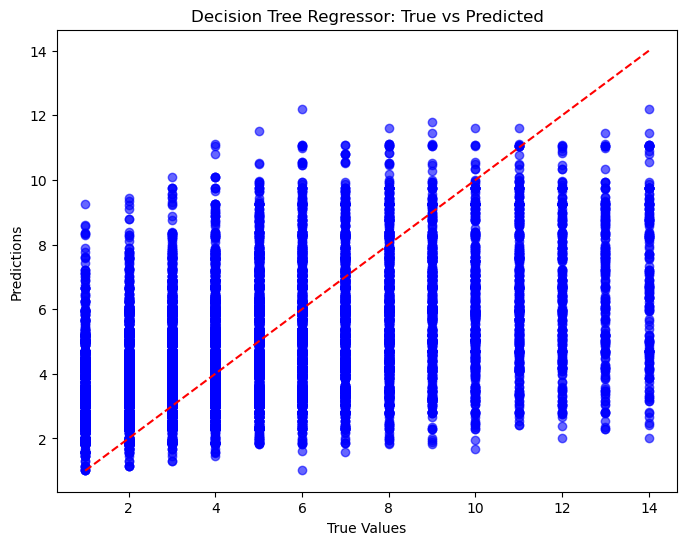

In [121]:
# # #  visualizing the output forDecision Tree Regressor model
import matplotlib.pyplot as plt
y_pred_dt = tree_model_2.predict(X_test)
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_dt, color='blue', alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--') 
plt.xlabel('True Values')
plt.ylabel('Predictions')
plt.title('Decision Tree Regressor: True vs Predicted')
plt.show()

In [122]:
# importing requires sklearn packages for implementing Gradient Boosting Regressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import cross_val_score,KFold
import numpy as np
# # #  Initialising and training Gradient Boosting Regressor
gboost_model_2 = GradientBoostingRegressor( subsample=1.0, n_estimators= 200, min_samples_split= 5, min_samples_leaf= 1, max_depth=5, learning_rate= 0.1)
# # # cross val 
kf = KFold(n_splits=6, shuffle=True, random_state=42)
cv_scores_mae_gb = -cross_val_score(gboost_model_2, X, y, cv=kf, scoring='neg_mean_absolute_error')
# # # fitting the model 
gboost_model_2.fit(X_train, y_train)

# Predictions
y_pred_gboost = gboost_model_2.predict(X_test)

# Evaluation
mae_gboost_2 = mean_absolute_error(y_test,y_pred_gboost)
mse_gboost_2 = mean_squared_error(y_test,y_pred_gboost)
rmse_gboost_2=np.sqrt(mse_gboost_2)


print(f"Gradient Boosting Regression MAE: {mae_gboost_2}")
print(f"Gradient Boosting Regression MSE: {mse_gboost_2}")
print(f"Gradient Boosting Regression RMSE:{rmse_gboost_2}")
print(f"Cross-Validation MAE Scores: {cv_scores_mae_gb}")             

Gradient Boosting Regression MAE: 1.7865827398371215
Gradient Boosting Regression MSE: 5.577205986924326
Gradient Boosting Regression RMSE:2.3616108881279163
Cross-Validation MAE Scores: [1.78326148 1.81541359 1.78980603 1.79890551 1.79063747 1.79542093]


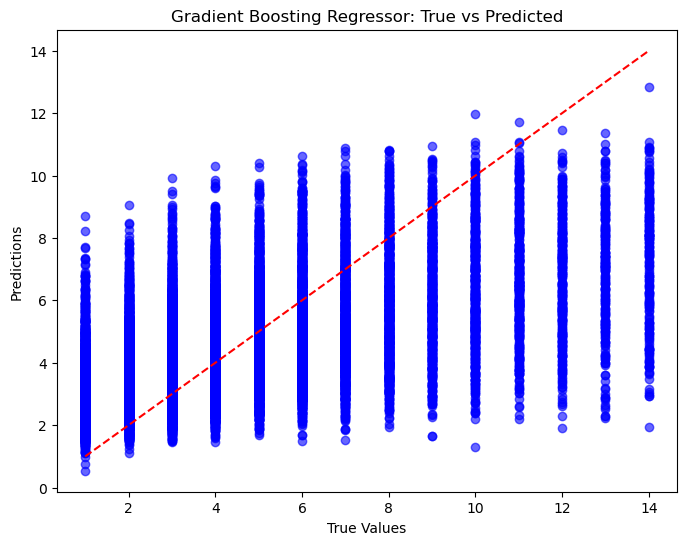

In [123]:
# # #  visualizing the output for Gradient Boosting Regressor

import matplotlib.pyplot as plt
y_pred_gboost = gboost_model_2.predict(X_test)
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_gboost, color='blue', alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--') 
plt.xlabel('True Values')
plt.ylabel('Predictions')
plt.title('Gradient Boosting Regressor: True vs Predicted')
plt.show()

In [124]:
# # # importing requires packages
import xgboost as xgb
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import cross_val_score,KFold
# # # Initialize and train XGBoost Regressor
xgboost_model_2 = xgb.XGBRegressor(n_estimators=500,learning_rate=0.05)          

# # #  doing cros val 

kf = KFold(n_splits=7, shuffle=True, random_state=42)
cv_scores_mae_xgb = -cross_val_score(xgboost_model_2, X, y, cv=kf, scoring='neg_mean_absolute_error')
# # # fitting the model 

xgboost_model_2.fit(X_train,y_train)

# # # Predictions
y_pred_xgboost = xgboost_model_2.predict(X_test)
# # # Evaluation

mae_xgboost_2 = mean_absolute_error(y_test,y_pred_xgboost)
mse_xgboost_2 = mean_squared_error(y_test,y_pred_xgboost)
rmse_xgboost_2 = np.sqrt(mse_xgboost_2)


print(f"XGBoost Regression MAE: {mae_xgboost_2}")
print(f"XGBoost Regression MSE: {mse_xgboost_2}")
print(f"XGBoost Regression RMSE: {rmse_xgboost_2}")
print(f"Cross-Validation MAE Scores: {cv_scores_mae_xgb}")

XGBoost Regression MAE: 1.7794932729971014
XGBoost Regression MSE: 5.549768916495278
XGBoost Regression RMSE: 2.355794752624956
Cross-Validation MAE Scores: [1.77084001 1.80865689 1.78221228 1.79176963 1.79136673 1.78168814
 1.78349421]


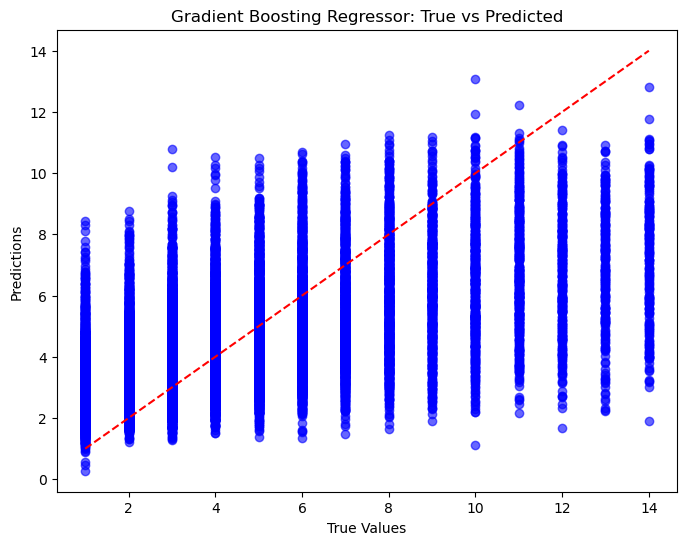

In [125]:
# # #  visualizing the output for XGboost  Regressor
import matplotlib.pyplot as plt
y_pred_xgboost = xgboost_model_2.predict(X_test)
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_xgboost, color='blue', alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--') 
plt.xlabel('True Values')
plt.ylabel('Predictions')
plt.title('Gradient Boosting Regressor: True vs Predicted')
plt.show()

In [126]:
# # # Sample comparison table after new featurs selection

import pandas as pd

results = {
    "Model": ["Linear Regression", "Decision Tree", "Gradient Boosting", "XGBoost"],
    "MAE": [mae_linear_2,mae_dt_2,mae_gboost_2,mae_xgboost_2],
    "MSE": [mse_linear_2,mse_dt_2,mse_gboost_2,mse_xgboost_2],
    "RMSE": [rmse_linear_2,rmse_dt_2,rmse_gboost_2,rmse_xgboost_2],
}


results_df = pd.DataFrame(results)


print(results_df)

               Model       MAE       MSE      RMSE
0  Linear Regression  1.927358  6.387857  2.527421
1      Decision Tree  1.848264  6.003576  2.450220
2  Gradient Boosting  1.786583  5.577206  2.361611
3            XGBoost  1.779493  5.549769  2.355795


+++++++++
### **Task 3.5: Hyperparameter Tuning**
Improve the quality of your implementations


#### 3.5.1: GridSearchCV for Systematic Hyperparameter Tuning
- Define Hyperparameter Grid for Different Models
- Define grids of hyperparameters for models such as Logistic Regression (for classification) and K-Means (for clustering).

In [127]:
# Define hyperparameter grid for KMeans
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

def silhouette_scorer(estimator, X):
    clusters = estimator.fit_predict(X)
    score = silhouette_score(X, clusters)
    return score

pca = PCA(n_components=0.95)  
X_train_reduced = pca.fit_transform(X_train)

param_grid = {
    'n_clusters': range(2, 4), 
    'init': ['k-means++'], 
    'n_init': [10],  
    'max_iter': [300]  
}

grid_search = GridSearchCV(
    KMeans(random_state=42),
    param_grid,
    scoring=silhouette_scorer,
    cv=3,  
    n_jobs=2  
)
grid_search.fit(X_train_reduced)
print("Best parameters:", grid_search.best_params_)
print("Best silhouette score:", grid_search.best_score_)

Best parameters: {'init': 'k-means++', 'max_iter': 300, 'n_clusters': 2, 'n_init': 10}
Best silhouette score: 0.9164861677188063


#### 3.5.2 Apply GridSearchCV with Cross-Validation
- Use GridSearchCV with cross-validation to perform hyperparameter tuning on both models.

#### 3.5.3: Nested Cross-Validation to Validate Stability of Hyperparameters

In [128]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.model_selection import cross_val_score, KFold

def silhouette_scorer(estimator, X_train_reduced):
    clusters = estimator.fit_predict(X_train_reduced)
    return silhouette_score(X_train_reduced, clusters)

outer_cv = KFold(n_splits=5, shuffle=True, random_state=42)

nested_cv_scores = cross_val_score(
    KMeans(n_clusters=3, random_state=42),  
    X_train_reduced,  
    cv=outer_cv,
    scoring=silhouette_scorer  
)

print("Nested CV Silhouette Scores for K-Means:", nested_cv_scores)
print("Mean Nested CV Silhouette Score:", nested_cv_scores.mean())


Nested CV Silhouette Scores for K-Means: [0.70407146 0.70916444 0.899074   0.8719042  0.89931673]
Mean Nested CV Silhouette Score: 0.8167061635138039


#### 3.5.4: Evaluate Tuned Models with Multiple Metrics
- Evaluate the tuned Logistic Regression model on both training and test sets.
- Use multiple metrics for classification (accuracy, F1-score) and clustering (silhouette score, Calinski-Harabasz).

In [44]:
from sklearn.metrics import silhouette_score, calinski_harabasz_score
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, random_state=42)  
kmeans.fit(X_train_reduced)
kmeans_labels = kmeans.predict(X_train_reduced)
silhouette = silhouette_score(X_train_reduced, kmeans_labels)
calinski_harabasz = calinski_harabasz_score(X_train_reduced, kmeans_labels)
print(f"KMeans - Silhouette Score: {silhouette:.4f}")
print(f"KMeans - Calinski-Harabasz Score: {calinski_harabasz:.4f}")


KMeans - Silhouette Score: 0.8990
KMeans - Calinski-Harabasz Score: 1079931.2957


+++++++++
### **Task 3.6: Model Selection**
- Compare and evaluate the implemented models and select the best ones.

#### 3.6.1: Compare and Choose the Best Model
- Compare the models using evaluation metrics (e.g., MSE for regression, F1-score for classification, Silhouette Score for clustering).
- Summarise the performance metrics of each model in a table and choose the model with the best performance for each task.

In [45]:
 ### Regression befor Feature Engineering and Feature Selection

results = {
    "Model": ["Linear Regression", "Decision Tree", "Gradient Boosting", "XGBoost"],                                                        
    "MAE": [mae_linear,mae_dt,mae_gboost,mae_xgboost],
    "MSE": [mse_linear,mse_dt,mse_gboost,mse_xgboost],
    "RMSE": [rmse_linear,rmse_dt,rmse_gboost,rmse_xgboost],}

results_df = pd.DataFrame(results)
print(f' Regression befor Feature Engineering and Feature Selection:')
print(results_df) 

 ### Regression after Feature Engineering and Feature Selection
results = {
    "Model": ["Linear Regression", "Decision Tree", "Gradient Boosting", "XGBoost"],
    "MAE": [mae_linear_2,mae_dt_2,mae_gboost_2,mae_xgboost_2],
    "MSE": [mse_linear_2,mse_dt_2,mse_gboost_2,mse_xgboost_2],
    "RMSE": [rmse_linear_2,rmse_dt_2,rmse_gboost_2,rmse_xgboost_2],}

print(f' Regression after Feature Engineering and Feature Selection:')
results_df = pd.DataFrame(results)
print(results_df)

 Regression befor Feature Engineering and Feature Selection:
               Model       MAE       MSE      RMSE
0  Linear Regression  1.917395  6.322751  2.514508
1      Decision Tree  1.833769  5.914079  2.431888
2  Gradient Boosting  1.794178  5.647350  2.376415
3            XGBoost  1.793466  5.636957  2.374228
 Regression after Feature Engineering and Feature Selection:
               Model       MAE       MSE      RMSE
0  Linear Regression  1.927358  6.387857  2.527421
1      Decision Tree  1.848264  6.003576  2.450220
2  Gradient Boosting  1.786577  5.577130  2.361595
3            XGBoost  1.779493  5.549769  2.355795


In [46]:
### Classification tasks befor Feature Engineering and Feature Selection
results = {
    "Model": ["Logistic Regression", "Random Forest", "K-Nearest Neighbors"],
    "Accuracy": [accuracy_logistic,accuracy_rf,accuracy_knn],
    "Precision": [precision_logistic,precision_rf, precision_knn],
    "Recall": [recall_logistic, recall_rf, recall_knn],
    "F1 Score": [f_1_score_logistic, f1_rf, f1_knn] }
print(f'Classification befor Feature Engineering and Feature Selection:')
results_df = pd.DataFrame(results)
print(results_df)
### Classification tasks after Feature Engineering and Feature Selection
results = {
    "Model": ["Logistic Regression", "Random Forest", "K-Nearest Neighbors"],
    "Accuracy": [accuracy_logistic_2,accuracy_rf_2,accuracy_knn_2],
    "Precision": [precision_logistic_2,precision_rf_2, precision_knn_2],
    "Recall": [recall_logistic_2, recall_rf_2, recall_knn_2],
    "F1 Score": [f_1_score_logistic_2, f1_rf_2, f1_knn_2]
}
print(f'Classification after Feature Engineering ,Feature Selection and hyperparameter tuning:')
results_df = pd.DataFrame(results)
print(results_df)


Classification befor Feature Engineering and Feature Selection:
                 Model  Accuracy  Precision    Recall  F1 Score
0  Logistic Regression  0.559448   0.835163  0.536390  0.653235
1        Random Forest  0.645180   0.826991  0.684555  0.749062
2  K-Nearest Neighbors  0.769480   0.785014  0.966785  0.866469
Classification after Feature Engineering ,Feature Selection and hyperparameter tuning:
                 Model  Accuracy  Precision    Recall  F1 Score
0  Logistic Regression  0.585585   0.824749  0.586423  0.685461
1        Random Forest  0.776997   0.781417  0.986282  0.871979
2  K-Nearest Neighbors  0.770708   0.783514  0.970331  0.866973


In [47]:
# # # Summary of Silhouette Scores
import pandas as pd

results = {
    "Clustering Method": ["K-Means",  ],
    "Silhouette Score": [kmean_silhouette]
}

results_df = pd.DataFrame(results)
print(results_df)

print(f' kmeans after hyperparameter tuning:')
print(grid_search.best_score_)


  Clustering Method  Silhouette Score
0           K-Means          0.787573
 kmeans after hyperparameter tuning:
0.9164861677188063


In [50]:
 # # # finalising best models
knn=accuracy_rf_2,precision_rf_2,recall_rf_2,f1_rf_2
knn_results_df = pd.DataFrame(knn)
print(f'best classification model:',knn_results_df)






best classification model:           0
0  0.776997
1  0.781417
2  0.986282
3  0.871979


In [49]:
xgb=mae_xgboost_2,mse_xgboost_2,rmse_xgboost_2
xgb_results_df = pd.DataFrame(xgb)
print(f'best regression model:',xgb_results_df)

best regression model:           0
0  1.779493
1  5.549769
2  2.355795


In [56]:


print(f'best clustering model:')
print(grid_search.best_score_)

best clustering model:
0.9164861677188063
